# Un décideur typé entraîné (encodeur de paires texte/option) égale-t-il un CamemBERT à classes fixes en français, et reste-t-il stable quand on change l'ordre, la formulation des libellés et les classes proposées ?

> **En bref.** Verdict impossible à cette échelle : la référence est à peine entraînée et reste au hasard. La stabilité à l'ordre est acquise par construction, donc peu informative sur les modèles de décision de la source. taux de bascule (permutation) : 0 [0 ; 0] pour Décideur typé (libellés fixes), contre 0 [0 ; 0] pour CamemBERT-base (classes fixes) (120 exemples de test, échelle réduite, chiffres indicatifs).

| | |
|---|---|
| **Question** | Un décideur typé encodeur (mmBERT-base, paires texte/option, 60 options) entraîné avec augmentation de libellés atteint une accuracy à au plus 3 points de CamemBERT-base sur les intentions vues, avec un taux de bascule sous permutation inférieur à 5 %, une accuracy supérieure à 50 % sur 10 intentions jamais vues à l'entraînement (impossible pour CamemBERT), mais s'effondre (accuracy proche du hasard, 1/60) sur libellés opaques. |
| **Référence** | CamemBERT-base fine-tuné — Classifieur à classes fixes : encodeur CamemBERT-base avec tête linéaire sur les 50 intentions d'entraînement, entraîné jusqu'à convergence avec sélection sur la validation. |
| **Nouvelle approche** | Décideur typé encodeur (paires texte/option) avec augmentation de libellés — Un encodeur lit chaque paire (texte, libellé de l'option) et produit un score ; un softmax avec température sur les options fournies donne une probabilité par option, sans tête de classes fixes. À l'entraînement, chaque libellé est tiré parmi plusieurs formulations. |
| **Données publiques** | [`mteb/amazon_massive_intent`](https://huggingface.co/datasets/mteb/amazon_massive_intent) (fr) |
| **Métrique principale** | taux de bascule (permutation) (à minimiser) |

**Sommaire** — 0. Mise en route · 1. La question · 2. Les données · 3. L'approche de référence · 4. La nouvelle approche · 5. Évaluation · 6. Analyse des résultats · 7. Bilan

**Trois façons d'exécuter ce notebook** (cellule de paramètres, section 0) :

| Réglage | À quoi ça sert |
|---|---|
| `PHASE = "public"`, `SCALE = "reduced"` | vérifier que tout fonctionne : quelques minutes sur CPU, sur un échantillon |
| `PHASE = "public"`, `SCALE = "full"` | reproduire les résultats publiés, sur tout le jeu public |
| `PHASE = "private"` | rejouer le même protocole sur vos données, dans votre environnement (voir le README) |

Les sorties affichées sont celles de l'échelle réduite (`SCALE = "reduced"`).

## 0. Mise en route

Trois réglages suffisent : la **phase** (quelles données), l'**échelle** (combien de données et quels modèles) et la **graine** (mêmes tirages, mêmes résultats). Le même code sert aux deux phases : seule la source des données change.

- `PHASE = "public"` charge le jeu public ; `PHASE = "private"` lit vos données d'après `PRIVATE_CONFIG` (cellule suivante) et appelle vos services internes. En phase `private`, aucune donnée brute n'est affichée.
- `SCALE = "reduced"` prend un petit échantillon et, si besoin, des modèles plus petits de la même famille : c'est un test de la mécanique, ses chiffres ne valent pas résultat. `SCALE = "full"` utilise tout le jeu.
- Les fonctions communes (chargement des données internes, appels de services, intervalles de confiance, figures, enregistrement des résultats) sont dans `helpers.py`, à côté du notebook.

Fonctions de `helpers.py` utilisées ici :

| Fonction | Rôle |
|---|---|
| `set_seed` | Graine unique pour random, numpy et torch (s'ils sont présents) : résultats reproductibles. |
| `device` | Matériel de calcul disponible : « cuda » (GPU NVIDIA), « mps » (GPU Apple) ou « cpu ». |
| `sample_size` | Nombre d'exemples à utiliser : `reduced` à l'échelle réduite, `full` (None = tout le jeu) à l'échelle complète. |
| `by_scale` | Valeur qui dépend de l'échelle : modèle substitut, nombre d'époques, de pas ou d'exemples. |
| `model_path` | Chemin à passer à `from_pretrained`, dans les deux phases : l'identifiant Hugging Face, ou son dossier local sous LOCAL_MODELS_DIR (org--nom ou org/nom), seul accessible dans un environnement sans Internet. |
| `load_private_data` | Jeu de la phase « private » : DataFrame aux colonnes attendues, lu dans PRIVATE_CONFIG['data'] (ou PRIVATE_DATA), fichier ou dossier (csv, tsv, parquet, jsonl, json, xlsx). |
| `preview` | Premières lignes en phase « public » ; en phase « private », seulement la structure (sauf SHOW_EXAMPLES=1). |
| `fingerprint` | Empreinte courte (sha256) d'un jeu de données, pour la traçabilité des résultats. |
| `timer` | Mesure une durée en millisecondes : `with timer(liste): ...` ajoute la durée à `liste`. |
| `latency_stats` | Médiane (p50) et 95e centile (p95) d'une liste de durées en millisecondes. |
| `bootstrap_ci` | Valeur de `metric(y_true, y_pred)` et son intervalle de confiance à 95 % par bootstrap : (valeur, bas, haut). |
| `save_results` | Valide puis écrit results_<phase>.json dans le dossier des résultats. Structure attendue : |
| `results_table` | Tableau comparatif : une ligne par approche, chaque métrique avec son intervalle de confiance. |
| `save_figure` | Enregistre la figure (figures/<name>.png), l'affiche avec sa légende et la ferme ; ne renvoie rien. |
| `plot_comparison` | Figure de synthèse : une barre par approche et par métrique, avec l'intervalle de confiance à 95 % quand il existe. Par défaut, la métrique principale puis jusqu'à trois autres métriques. Une métrique sans objet pour une approche (None) n'a pas de barre pour elle. |

In [1]:
PHASE = "public"        # "public" : jeu public ; "private" : vos données, dans votre environnement
SCALE = "reduced"       # "reduced" : échantillon, quelques minutes sur CPU ; "full" : tout le jeu
SEED = 42               # graine : mêmes tirages, mêmes résultats
OUTPUT_DIR = "outputs"  # résultats (results_<phase>.json) et figures

### Configuration pour vos données

À modifier seulement pour `PHASE = "private"`. Chaque entrée est expliquée en commentaire ; les valeurs par défaut viennent des variables d'environnement décrites dans `private.env.example`. Au lancement, une liste de contrôle vérifie le jeu, les colonnes, les modèles et les services, et s'arrête sur ce qui manque avant tout calcul.

In [3]:
# Configuration pour vos données (PHASE = "private") : seule cellule à adapter.
# Les valeurs par défaut viennent de l'environnement (modèle : private.env.example).
# Aucune clé ici : elle vient de <SERVICE>_API_KEY, d'un fichier de secret monté (<SERVICE>_API_KEY_FILE) ou d'une saisie masquée.
import os

PRIVATE_CONFIG = {
    # Jeu de données : un fichier (csv, tsv, parquet, jsonl, json, xlsx) ou un dossier de fichiers de même structure.
    "data": os.environ.get("PRIVATE_DATA", ""),
    # Colonne attendue par le notebook -> nom de la colonne dans votre jeu (ne modifier que la partie droite).
    "columns": {'text': 'text', 'reason': 'reason', 'sub_reason': 'sub_reason', 'reason_description': 'reason_description', 'received_at': 'received_at'},
    # Colonnes qui contiennent des chemins de fichiers (relatifs au fichier de données qui les cite, ou absolus).
    "path_columns": [],
    "max_rows": None,                         # plafond facultatif (échantillon aléatoire reproductible)
    "csv": {"sep": None, "encoding": None},   # None : séparateur et encodage devinés (« ; », Windows-1252…)
    # Poids des modèles copiés localement (dossiers org--nom/, script download_models.py), pour travailler sans Internet.
    "models_dir": os.environ.get("LOCAL_MODELS_DIR", ""),
    "models": {'reduced': ['almanach/camembert-base', 'jhu-clsp/mmBERT-small'], 'full': ['almanach/camembert-base', 'jhu-clsp/mmBERT-base']},
    # Autorité de certification d'entreprise (fichier PEM) pour les appels HTTPS internes ; vide sinon.
    "ca_bundle": os.environ.get("SSL_CERT_FILE", ""),
}

### Dépendances et initialisation

Les versions exactes utilisées pour les résultats publiés sont dans `requirements.txt`. Les paquets propres à cette expérience s'installent depuis le notebook avec `INSTALL_DEPENDENCIES=1`.

In [4]:
# Paquets propres à cette expérience (en plus de requirements.txt).
EXTRA_PACKAGES = []
import os, subprocess, sys
if EXTRA_PACKAGES and os.environ.get("INSTALL_DEPENDENCIES") == "1":
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *EXTRA_PACKAGES])

In [5]:
from helpers import *  # fonctions communes (voir le tableau ci-dessus)

configure(phase=PHASE, scale=SCALE, seed=SEED, output_dir=OUTPUT_DIR)
apply_private_config(PRIVATE_CONFIG)  # phase private : liste de contrôle, arrêt si quelque chose manque
prepare_environment()                 # télémétrie coupée ; hors ligne si les modèles sont locaux
use_plot_style()
show_configuration()

PHASE=public  SCALE=reduced  SEED=42  device=cpu  python=3.12.16
service LLM (convention OpenAI)               LLMAAS_BASE_URL=—  LLMAAS_MODEL=—  clé absente
service de transcription (convention OpenAI)  STTAAS_BASE_URL=—  STTAAS_MODEL=—  clé absente
données internes : —  modèles locaux : —


## 1. La question

Pour ranger un message dans une catégorie, on fine-tune souvent un encodeur français (**CamemBERT**) avec une tête à **classes fixes** : rapide et précis, mais chaque catégorie ajoutée ou renommée oblige à réentraîner le modèle.

Les **modèles de décision** récents (famille Drex, par exemple) proposent une autre interface. On fournit à chaque requête **la liste des options**, et le modèle rend **une probabilité par option**, sans rédiger de texte. On teste ici une version compacte de cette idée, entraînée sur nos données : un **décideur typé**.

### L'idée, avec une analogie

CamemBERT ressemble à un trieur postal qui a appris par cœur 50 casiers. Le décideur lit l'étiquette de chaque casier et juge si la lettre lui correspond. Il peut donc traiter un casier nouveau, à condition que son étiquette soit parlante.

1. On construit une paire (texte, libellé de l'option) pour chaque option proposée.
2. Un encodeur multilingue (mmBERT) lit la paire et produit un **score**.
3. Un **softmax avec température** sur les scores des options fournies donne une probabilité par option.
4. À l'entraînement, on écrit chaque libellé sous plusieurs formes (**augmentation de libellés**), pour que le modèle ne dépende pas d'une seule formulation.

### Ce que la comparaison permet de décider

- Sur les intentions vues à l'entraînement, le décideur est-il **aussi précis** que CamemBERT (à 3 points près) ?
- Sa décision reste-t-elle la même si l'on **change l'ordre des options** (taux de bascule sous 5 %) ?
- Reconnaît-il des **intentions jamais vues** (plus de 50 %) ? CamemBERT en est incapable par construction.
- Que devient-il avec des libellés **reformulés, tronqués ou opaques** ? On s'attend à ce qu'il tombe au niveau du hasard avec des codes sans signification.

## 2. Les données

### Outils

On importe les bibliothèques utilisées dans tout le notebook. Les barres de progression et les messages verbeux sont coupés pour que les sorties restent lisibles.

In [6]:
import contextlib
import gc
import math
import time

import datasets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import transformers
from datasets import load_dataset
from scipy.stats import binomtest
from sklearn.metrics import f1_score
from transformers import (AutoConfig, AutoModel, AutoModelForSequenceClassification,
                          AutoTokenizer, get_linear_schedule_with_warmup)
from transformers.utils import logging as hf_logging

datasets.disable_progress_bars()
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Réglages des données

Le jeu public est **MASSIVE** en français : des requêtes d'assistant vocal traduites par des humains, réparties en 60 **intentions** regroupées en 18 **scénarios**. Le préfixe de chaque intention donne son scénario (`alarm_set` → `alarm`).

On retire 10 intentions de l'entraînement. Elles servent à mesurer ce que devient chaque modèle face à une **classe jamais vue**.

In [7]:
DATASET_ID = "mteb/amazon_massive_intent"          # MASSIVE, licence apache-2.0
DATASET_CONFIG = "fr"                               # sous-ensemble français
N_UNSEEN_INTENTS = 10                               # intentions retirées de l'entraînement
TRAIN_SIZE = sample_size(reduced=320, full=None)    # textes d'entraînement (None = tout le jeu)
VAL_SIZE = sample_size(reduced=60, full=400)        # validation : point d'arrêt et température
TEST_SIZE = sample_size(reduced=120, full=1500)     # questions de test, les mêmes pour toutes les approches
UNSEEN_TEST_SHARE = 0.2                             # part du test tirée parmi les intentions jamais vues
N_OPTIONS_EVAL = by_scale(8, 60)                    # options proposées par question au test

### Un second vocabulaire de libellés

La clé anglaise (`alarm set`) est le libellé de base. Pour tester la sensibilité à la **formulation**, on écrit aussi chaque intention en **mots français**. Cette traduction est faite par règle : elle n'a pas été validée par des experts.

In [8]:
FRENCH_LABELS = {
    "alarm_query": "consulter alarme", "alarm_remove": "supprimer alarme", "alarm_set": "régler alarme",
    "audio_volume_down": "baisser volume", "audio_volume_mute": "couper son",
    "audio_volume_other": "autre réglage audio", "audio_volume_up": "monter volume",
    "calendar_query": "consulter agenda", "calendar_remove": "supprimer événement agenda",
    "calendar_set": "ajouter événement agenda", "cooking_query": "question cuisine",
    "cooking_recipe": "recette de cuisine", "datetime_convert": "convertir fuseau horaire",
    "datetime_query": "date et heure", "email_addcontact": "ajouter contact courriel",
    "email_query": "consulter courriels", "email_querycontact": "consulter contact",
    "email_sendemail": "envoyer courriel", "general_greet": "salutation", "general_joke": "raconter blague",
    "general_quirky": "discussion libre", "iot_cleaning": "lancer aspirateur", "iot_coffee": "préparer café",
    "iot_hue_lightchange": "changer couleur lumière", "iot_hue_lightdim": "baisser lumière",
    "iot_hue_lightoff": "éteindre lumière", "iot_hue_lighton": "allumer lumière",
    "iot_hue_lightup": "augmenter lumière", "iot_wemo_off": "éteindre prise", "iot_wemo_on": "allumer prise",
    "lists_createoradd": "créer ou compléter liste", "lists_query": "consulter liste",
    "lists_remove": "retirer de liste", "music_dislikeness": "musique pas aimée",
    "music_likeness": "musique aimée", "music_query": "quelle musique", "music_settings": "réglage lecture musique",
    "news_query": "actualités", "play_audiobook": "lire livre audio", "play_game": "lancer jeu",
    "play_music": "jouer musique", "play_podcasts": "lire podcast", "play_radio": "écouter radio",
    "qa_currency": "taux de change", "qa_definition": "définition de mot", "qa_factoid": "question de culture",
    "qa_maths": "calcul", "qa_stock": "cours de bourse", "recommendation_events": "suggérer sortie",
    "recommendation_locations": "suggérer lieu", "recommendation_movies": "suggérer film",
    "social_post": "publier sur réseau social", "social_query": "consulter réseau social",
    "takeaway_order": "repas à emporter", "takeaway_query": "question repas livré",
    "transport_query": "info transport", "transport_taxi": "réserver taxi", "transport_ticket": "réserver billet",
    "transport_traffic": "état circulation", "weather_query": "météo",
}

### La table des libellés

Chaque classe reçoit plusieurs **présentations** :
- `key` : la clé lisible ;
- `french` : les mots français ;
- `truncated` : un **sigle** fait des 3 premières lettres de chaque mot ;
- `opaque` : un **code sans signification** (`OPT-017`) ;
- `scenario_key` : le scénario suivi de l'intention.

Avec les codes opaques, on vérifie que le modèle s'appuie bien sur le **sens** du libellé.

In [9]:
def truncated_labels(keys: list[str]) -> list[str]:
    """Sigle tronqué : 3 premières lettres de chaque mot ; un numéro départage les doublons."""
    counts: dict[str, int] = {}
    labels = []
    for key in keys:
        base = " ".join(word[:3] for word in key.split())
        counts[base] = counts.get(base, 0) + 1
        labels.append(base if counts[base] == 1 else f"{base} {counts[base]}")
    return labels


def build_label_table(intents: list[str], scenario_of: dict, key_of: dict, french_of: dict,
                      seed: int) -> pd.DataFrame:
    """Table des libellés : une ligne par classe, une colonne par vocabulaire de présentation."""
    table = pd.DataFrame(index=pd.Index(sorted(intents), name="intent"))
    table["scenario"] = [str(scenario_of[i]) for i in table.index]
    table["key"] = [str(key_of[i]) for i in table.index]
    table["french"] = [str(french_of[i]) for i in table.index]
    table["truncated"] = truncated_labels(table["key"].tolist())
    codes = np.random.default_rng(seed).permutation(len(table)) + 1  # codes mélangés : aucun indice d'ordre
    table["opaque"] = [f"OPT-{code:03d}" for code in codes]
    table["scenario_key"] = table["scenario"] + " : " + table["key"]
    return table

### Découpage commun aux deux phases

`prepare_splits` est la même fonction pour les deux phases. Elle procède en trois temps :
1. elle tire au hasard (avec la graine) les intentions **jamais vues** ;
2. elle les retire de l'entraînement et de la validation ;
3. elle compose un test qui mélange intentions vues et jamais vues.

L'échantillonnage est **équilibré par classe**, pour qu'aucune intention ne domine le petit échantillon de l'échelle réduite.

In [10]:
def stratified_sample(frame: pd.DataFrame, n: int | None, seed: int) -> pd.DataFrame:
    """Échantillon équilibré entre classes (n=None : tout le jeu, mélangé)."""
    shuffled = frame.sample(frac=1, random_state=seed)
    if n is None or n >= len(frame):
        return shuffled.reset_index(drop=True)
    per_class = max(1, math.ceil(n / max(1, frame["intent"].nunique())))
    balanced = shuffled.groupby("intent", sort=True).head(per_class)
    return balanced.sample(n=min(n, len(balanced)), random_state=seed).reset_index(drop=True)


def prepare_splits(train_pool: pd.DataFrame, val_pool: pd.DataFrame, test_pool: pd.DataFrame,
                   label_table: pd.DataFrame, seed: int):
    """Choisit les classes jamais vues puis échantillonne les trois sous-ensembles.

    Retour : (train, val, test, classes vues, classes jamais vues)."""
    intents = list(label_table.index)
    rng = np.random.default_rng(seed)
    n_unseen = min(N_UNSEEN_INTENTS, len(intents) // 5)
    held_out = {str(i) for i in rng.choice(intents, size=n_unseen, replace=False)}
    seen = [i for i in intents if i not in held_out and (train_pool["intent"] == i).any()]
    unseen = [i for i in intents if i not in seen]
    train = stratified_sample(train_pool[train_pool["intent"].isin(seen)], TRAIN_SIZE, seed)
    val = stratified_sample(val_pool[val_pool["intent"].isin(seen)], VAL_SIZE, seed)
    test_pool = test_pool[test_pool["intent"].isin(intents)]
    n_test = len(test_pool) if TEST_SIZE is None else min(TEST_SIZE, len(test_pool))
    test_unseen = stratified_sample(test_pool[test_pool["intent"].isin(unseen)],
                                    round(n_test * UNSEEN_TEST_SHARE), seed)
    test_seen = stratified_sample(test_pool[test_pool["intent"].isin(seen)], n_test - len(test_unseen), seed)
    test = pd.concat([test_seen, test_unseen]).sample(frac=1, random_state=seed).reset_index(drop=True)
    for frame in (train, val, test):
        frame["scenario"] = frame["intent"].map(label_table["scenario"])
        frame["is_seen"] = frame["intent"].isin(seen)
    return train, val, test, seen, unseen

### Chargement du jeu public

Le jeu est lu au format parquet depuis le Hub. On vérifie que les colonnes attendues sont présentes, puis on garde le texte et le nom d'intention (`label_text`). Cette cellule ne s'exécute qu'en phase publique.

In [11]:
if PHASE == "public":
    raw = load_dataset(DATASET_ID, DATASET_CONFIG)
    frames = {}
    for split in ["train", "validation", "test"]:
        df = raw[split].to_pandas()
        missing = {"text", "label_text"} - set(df.columns)
        assert not missing, f"colonnes absentes : {missing}"
        if "lang" in df.columns:
            df = df[df["lang"].astype(str) == DATASET_CONFIG]
        frames[split] = pd.DataFrame({"text": df["text"].astype(str).str.strip(),
                                      "intent": df["label_text"].astype(str)})
    intents = sorted(frames["train"]["intent"].unique())
    label_table = build_label_table(
        intents,
        scenario_of={i: i.split("_")[0] for i in intents},  # le préfixe donne le scénario parent
        key_of={i: i.replace("_", " ") for i in intents},
        french_of={i: FRENCH_LABELS.get(i, i.replace("_", " ")) for i in intents},
        seed=SEED)
    train_df, val_df, test_df, seen_intents, unseen_intents = prepare_splits(
        frames["train"], frames["validation"], frames["test"], label_table, SEED)
    DATASET_INFO = {"name": DATASET_ID, "config": DATASET_CONFIG, "split": "test"}
    print(f"{len(intents)} intentions, {label_table['scenario'].nunique()} scénarios ; "
          f"sans traduction française : {sorted(set(intents) - set(FRENCH_LABELS)) or 'aucune'}")

60 intentions, 18 scénarios ; sans traduction française : aucune


### Contrôles et figure

Deux fonctions servent aux deux phases :
- `describe_splits` donne les effectifs, le nombre de classes, le minimum par classe et la longueur des textes ;
- `plot_data_overview` montre la répartition par scénario et la longueur des questions de test.

In [12]:
def describe_splits() -> pd.DataFrame:
    """Effectifs, classes et longueur des textes (en mots) par sous-ensemble."""
    rows = []
    for name, frame in [("entraînement", train_df), ("validation", val_df), ("test", test_df)]:
        words = frame["text"].str.split().str.len()
        rows.append({"sous-ensemble": name, "textes": len(frame), "classes": frame["intent"].nunique(),
                     "dont jamais vues": int((~frame["is_seen"]).sum()),
                     "min par classe": int(frame["intent"].value_counts().min()),
                     "mots (médiane)": float(words.median()), "mots (max)": int(words.max())})
    return pd.DataFrame(rows)


def plot_data_overview() -> None:
    """Figure : textes d'entraînement par scénario et longueur des questions de test."""
    fig, (left, right) = plt.subplots(1, 2, figsize=(13, 5))
    counts = train_df["scenario"].value_counts().sort_values()
    left.barh(counts.index, counts.values, color=COLORS["reference"])
    left.set(title="Textes d'entraînement par scénario", xlabel="nombre de textes", ylabel="scénario")
    words = test_df["text"].str.split().str.len()
    bins = np.arange(0, words.max() + 2) if words.max() <= 60 else 30
    right.hist([words[test_df["is_seen"]].to_numpy(), words[~test_df["is_seen"]].to_numpy()], bins=bins,
               stacked=True, color=[COLORS["reference"], COLORS["new"]],
               label=["intention vue", "intention jamais vue"])
    right.set(title="Longueur des questions de test", xlabel="longueur (mots)", ylabel="nombre de questions")
    right.legend()
    save_figure(fig, "data_overview",
                "À gauche, le nombre de textes d'entraînement par scénario (classes jamais vues exclues). "
                "À droite, la longueur des questions de test, en distinguant les intentions vues et jamais vues.")

### Aperçu du jeu public

On affiche les effectifs, les intentions réservées, la figure et quelques exemples, puis les premières lignes de la table des libellés.

,sous-ensemble,textes,classes,dont jamais vues,min par classe,mots (médiane),mots (max)
0,entraînement,320,50,0,4,7.0,26
1,validation,60,41,0,1,7.0,20
2,test,120,59,24,1,6.0,15


Intentions jamais vues à l'entraînement : audio_volume_mute, audio_volume_other, cooking_recipe, iot_hue_lightchange, music_likeness, play_music, recommendation_events, takeaway_query, transport_taxi, transport_ticket


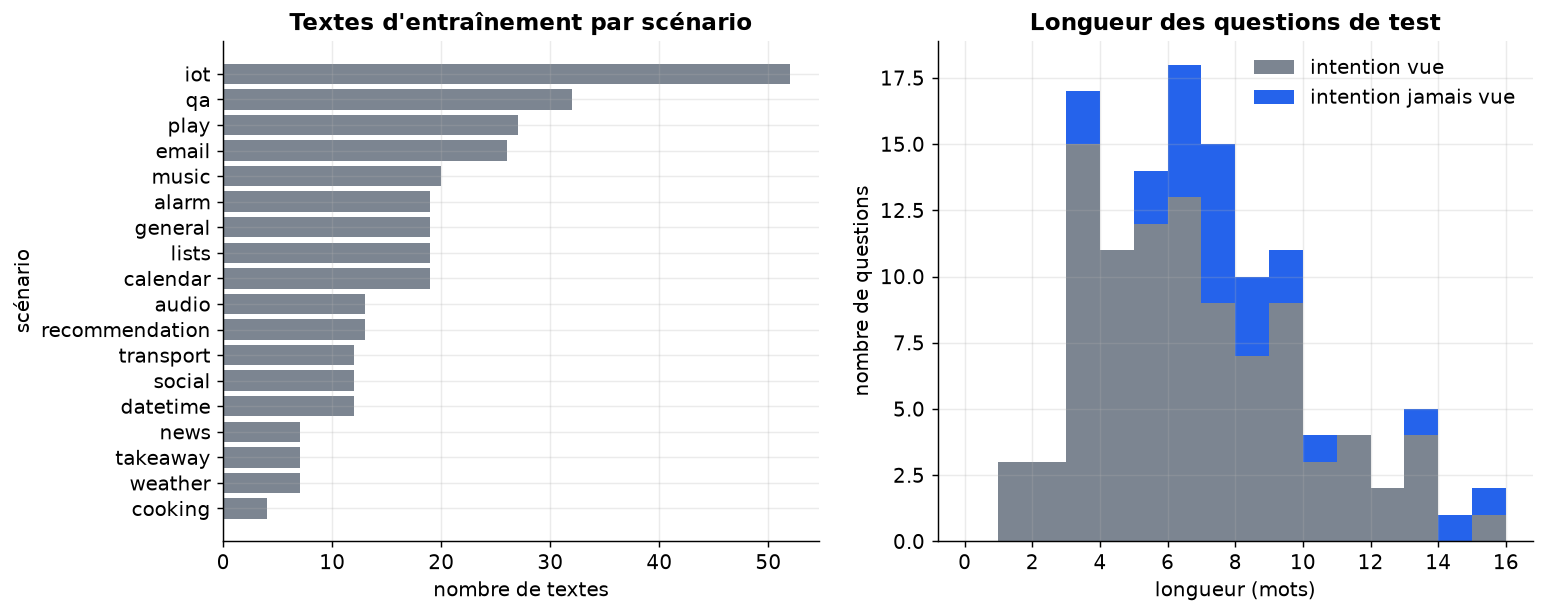

*Figure — À gauche, le nombre de textes d'entraînement par scénario (classes jamais vues exclues). À droite, la longueur des questions de test, en distinguant les intentions vues et jamais vues.*

,scenario,key,french,truncated,opaque,scenario_key
intent,,,,,,
alarm_query,alarm,alarm query,consulter alarme,ala que,OPT-029,alarm : alarm query
alarm_remove,alarm,alarm remove,supprimer alarme,ala rem,OPT-056,alarm : alarm remove
alarm_set,alarm,alarm set,régler alarme,ala set,OPT-019,alarm : alarm set
audio_volume_down,audio,audio volume down,baisser volume,aud vol dow,OPT-025,audio : audio volume down
audio_volume_mute,audio,audio volume mute,couper son,aud vol mut,OPT-008,audio : audio volume mute
audio_volume_other,audio,audio volume other,autre réglage audio,aud vol oth,OPT-018,audio : audio volume other


In [13]:
if PHASE == "public":
    display(describe_splits())
    print("Intentions jamais vues à l'entraînement :", ", ".join(unseen_intents))
    plot_data_overview()
    preview(test_df[["text", "intent", "scenario", "is_seen"]], n=5)
    display(label_table.head(6))

### Colonnes attendues et catalogue factice

Les données internes comportent cinq colonnes :
- un texte ;
- un **motif** (niveau 1), qui joue le rôle du scénario ;
- un **sous-motif** (niveau 2), qui joue le rôle de l'intention ;
- sa description en jargon interne, qui remplace le vocabulaire « mots français » ;
- une date.

Pour la répétition, on génère un jeu **entièrement factice** à partir d'un petit catalogue de gabarits. Il ne contient aucune donnée réelle.

In [14]:
PRIVATE_COLUMNS = {
    "text": "Message ou e-mail client anonymisé",
    "reason": "Motif (niveau 1), libellé",
    "sub_reason": "Sous-motif (niveau 2), libellé exact",
    "reason_description": "Description courte du sous-motif, avec le jargon interne",
    "received_at": "Date de réception, pour le découpage temporel",
}

FAKE_CATALOG = [  # (motif, sous-motif, description, gabarits de messages)
    ("Carte de paiement", "Opposition carte", "Mise en opposition après perte ou vol (OPPO)",
     ["J'ai perdu ma carte {when}, pouvez-vous la bloquer ?", "Ma carte a été volée {when}, je veux faire opposition."]),
    ("Carte de paiement", "Plafond carte", "Relèvement temporaire du plafond de paiement (PLAF)",
     ["Je dois payer {amount} € et mon plafond est trop bas.", "Pouvez-vous augmenter mon plafond pour {amount} € ?"]),
    ("Carte de paiement", "Paiement refusé", "Transaction refusée au terminal (REFUS TPE)",
     ["Mon paiement de {amount} € a été refusé {when}.", "Ma carte ne passe plus chez les commerçants depuis {when}."]),
    ("Compte", "Relevé de compte", "Demande de relevé ou d'historique (RLV)",
     ["Je voudrais mon relevé de compte du mois dernier.", "Pouvez-vous m'envoyer l'historique depuis {when} ?"]),
    ("Compte", "Clôture de compte", "Fermeture du compte à la demande du titulaire (CLOT)",
     ["Je souhaite fermer mon compte.", "Merci de clôturer mon compte joint avant {when}."]),
    ("Compte", "Changement d'adresse", "Mise à jour des coordonnées postales (MAJ COORD)",
     ["J'ai déménagé {when}, voici ma nouvelle adresse.", "Comment modifier mon adresse postale ?"]),
    ("Virement", "Virement non reçu", "Virement entrant attendu mais non crédité (VIR ATT)",
     ["Le virement de {amount} € attendu {when} n'est pas arrivé.", "Je n'ai pas reçu les {amount} € envoyés {when}."]),
    ("Virement", "Ajout bénéficiaire", "Enregistrement d'un nouveau bénéficiaire (BENEF)",
     ["Je n'arrive pas à ajouter un bénéficiaire.", "Le code pour valider le bénéficiaire ne m'arrive pas."]),
    ("Virement", "Virement instantané", "Question sur le virement instantané et ses frais (VIR INST)",
     ["Le virement instantané de {amount} € est-il payant ?", "Pourquoi mon virement instantané est bloqué {when} ?"]),
    ("Crédit", "Échéancier", "Consultation ou report d'échéance (ECH)",
     ["Puis-je décaler l'échéance prévue {when} ?", "Quel est le montant de ma prochaine mensualité ?"]),
    ("Crédit", "Remboursement anticipé", "Remboursement anticipé partiel ou total (RA)",
     ["Je veux rembourser {amount} € par anticipation.", "Combien coûterait un remboursement total de mon crédit ?"]),
    ("Contact", "Prise de rendez-vous", "Demande de rendez-vous avec un conseiller (RDV)",
     ["Je voudrais un rendez-vous avec mon conseiller {when}.", "Est-il possible de me rappeler {when} ?"]),
    ("Contact", "Réclamation frais", "Contestation de frais prélevés (RECLA FRAIS)",
     ["On m'a prélevé {amount} € de frais sans explication.", "Je conteste les frais de {amount} € débités {when}."]),
]

### Générateur de données factices

`make_fake_data(n)` tire un sous-motif au hasard, remplit un gabarit (montant, moment), ajoute une formule d'ouverture et de clôture, puis une date répartie sur 18 mois. On obtient environ 70 textes par sous-motif, assez pour que toutes les étapes tournent.

In [15]:
def make_fake_data(n: int) -> pd.DataFrame:
    """Jeu factice plausible aux colonnes attendues (aucune donnée réelle)."""
    rng = np.random.default_rng(SEED)
    openings = ["", "Bonjour, ", "Bonjour madame, monsieur, ", "Bonsoir, "]
    closings = ["", " Merci.", " Cordialement.", " Merci d'avance pour votre aide."]
    moments = ["hier", "ce matin", "lundi dernier", "la semaine dernière", "le 3 du mois"]
    start, span_minutes = pd.Timestamp("2025-01-01"), 540 * 24 * 60
    rows = []
    for _ in range(n):
        reason, sub_reason, description, templates = FAKE_CATALOG[rng.integers(len(FAKE_CATALOG))]
        body = templates[rng.integers(len(templates))].format(
            when=moments[rng.integers(len(moments))], amount=int(rng.integers(20, 5000)))
        rows.append({"text": openings[rng.integers(4)] + body + closings[rng.integers(4)],
                     "reason": reason, "sub_reason": sub_reason, "reason_description": description,
                     "received_at": start + pd.Timedelta(minutes=int(rng.integers(span_minutes)))})
    return pd.DataFrame(rows)

### Chargement des données internes et découpage temporel

Le jeu est relu depuis un fichier. On convertit donc chaque type explicitement et on écarte les lignes vides ou sans date. Les classes sont **déduites des données**.

Le découpage suit le temps :
- les **20 % les plus récents** forment le test ;
- la fin de la période précédente sert de validation.

On applique ensuite le même `prepare_splits` qu'en phase publique.

In [16]:
TEST_PERIOD_SHARE = 0.2   # part la plus récente réservée au test
VAL_PERIOD_SHARE = 0.15   # fin de la période d'entraînement réservée à la validation

if PHASE == "private":
    private_df = load_private_data(PRIVATE_COLUMNS, make_fake_data, n_fake=900)
    for column in ["text", "reason", "sub_reason", "reason_description"]:
        private_df[column] = private_df[column].astype(str).str.strip()
    private_df["received_at"] = pd.to_datetime(private_df["received_at"], errors="coerce", utc=True)
    private_df = private_df[(private_df["text"] != "") & (private_df["sub_reason"] != "")
                            & private_df["received_at"].notna()]
    by_class = private_df.groupby("sub_reason")
    intents = sorted(by_class.groups)
    label_table = build_label_table(
        intents,
        scenario_of=by_class["reason"].agg(lambda s: s.mode().iloc[0]).to_dict(),
        key_of={i: i for i in intents},
        french_of=by_class["reason_description"].agg(lambda s: s.mode().iloc[0]).to_dict(),
        seed=SEED)
    ordered = (private_df.sort_values(["received_at", "text"], kind="stable")
               .rename(columns={"sub_reason": "intent"})[["text", "intent"]])
    n_before_test = int(len(ordered) * (1 - TEST_PERIOD_SHARE))
    n_train = int(n_before_test * (1 - VAL_PERIOD_SHARE))
    train_df, val_df, test_df, seen_intents, unseen_intents = prepare_splits(
        ordered.iloc[:n_train], ordered.iloc[n_train:n_before_test], ordered.iloc[n_before_test:],
        label_table, SEED)
    DATASET_INFO = {"name": "données internes", "config": "sous-motifs", "split": "période de test"}
    print(f"{len(intents)} sous-motifs, {label_table['scenario'].nunique()} motifs, "
          f"{len(unseen_intents)} réservés comme jamais vus")
    display(describe_splits())
    plot_data_overview()
    preview(test_df[["text", "intent", "scenario", "is_seen"]], n=3)

## 3. L'approche de référence

### Réglages communs

Ces réglages valent pour les deux approches :
- le matériel de calcul ;
- la **précision mixte** (calcul en float16, seulement sur GPU NVIDIA) ;
- la longueur maximale des entrées en tokens ;
- l'**empreinte** du jeu de test, pour la traçabilité.

In [17]:
DEVICE = device()
USE_FP16 = DEVICE == "cuda"     # précision mixte seulement sur GPU NVIDIA
WARMUP_SHARE = 0.1              # part des pas en montée progressive du taux d'apprentissage
MAX_LENGTH = by_scale(48, 64)   # tokens par entrée (texte seul ou paire texte/option)
all_intents = list(label_table.index)
DATA_FINGERPRINT = fingerprint(test_df[["text", "intent"]])


def autocast_context():
    """Précision mixte float16 sur GPU, calcul float32 ordinaire sinon."""
    return torch.autocast("cuda", dtype=torch.float16) if USE_FP16 else contextlib.nullcontext()


def free_memory() -> None:
    """Libère la mémoire entre deux entraînements."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


print(f"Calcul sur {DEVICE}, précision mixte : {USE_FP16}, empreinte du test : {DATA_FINGERPRINT}")

Calcul sur cpu, précision mixte : False, empreinte du test : 4016bfb45386d22b


### Probabilités, température et calibration

- **Softmax avec température** : $p_k = \exp(s_k/T) / \sum_j \exp(s_j/T)$. Une température $T > 1$ adoucit des probabilités trop sûres d'elles. On choisit $T$ sur la validation, là où la log-vraisemblance est la meilleure.
- **ECE** (erreur de calibration attendue) : on range les prédictions en 15 intervalles de confiance. Dans chaque intervalle, on compare la confiance moyenne et la part de réponses justes, puis on fait la moyenne pondérée des écarts.

In [18]:
def softmax(scores: np.ndarray, temperature: float = 1.0) -> np.ndarray:
    """Softmax numériquement stable sur le dernier axe, avec température."""
    z = np.asarray(scores, dtype=np.float64) / temperature
    z = z - z.max(axis=-1, keepdims=True)
    exp = np.exp(z)
    return exp / exp.sum(axis=-1, keepdims=True)


def fit_temperature(score_lists: list[np.ndarray], targets: list[int]) -> float:
    """Température qui minimise la log-vraisemblance négative de la validation (grille logarithmique)."""
    grid = np.exp(np.linspace(np.log(0.05), np.log(20.0), 120))
    losses = [-np.mean([np.log(softmax(s, t)[y] + 1e-12) for s, y in zip(score_lists, targets)]) for t in grid]
    return float(grid[int(np.argmin(losses))])


def expected_calibration_error(correct, confidence, n_bins: int = 15) -> float:
    """ECE : écart moyen pondéré entre confiance affichée et précision réelle, par intervalle."""
    correct, confidence = np.asarray(correct, float), np.asarray(confidence, float)
    edges = np.linspace(0, 1, n_bins + 1)
    bins = np.clip(np.digitize(confidence, edges[1:-1], right=True), 0, n_bins - 1)
    ece = 0.0
    for b in range(n_bins):
        mask = bins == b
        if mask.any():
            ece += mask.mean() * abs(correct[mask].mean() - confidence[mask].mean())
    return float(ece)

### Référence : réglages et longueur des entrées

La référence est **CamemBERT-base**, surmonté d'une tête linéaire sur les intentions vues. On reprend un réglage classique : taux d'apprentissage $3\cdot10^{-5}$, lots de 32, 6 époques à l'échelle complète, et l'on garde la meilleure époque sur la validation.

Avant tout entraînement, on mesure la longueur des questions **en tokens**. Il faut vérifier que le plafond ne coupe pas les entrées, dans chaque classe.

In [19]:
REF_MODEL_ID = "almanach/camembert-base"   # encodeur français de référence
REF_EPOCHS = by_scale(1, 6)                # époques (meilleure retenue sur la validation)
REF_LEARNING_RATE = 3e-5                   # taux classique pour un fine-tuning d'encodeur
REF_BATCH_SIZE = 32                        # textes par pas d'entraînement
PREDICT_BATCH_SIZE = 64                    # textes par lot à l'inférence


def token_length_report(tokenizer, texts: list[str], groups: list[str], pair_labels: list[str] | None = None) -> pd.Series:
    """Mesure les longueurs en tokens et renvoie, par classe, la part d'entrées non coupées."""
    encoded = tokenizer(texts, pair_labels, truncation=False)
    lengths = np.array([len(ids) for ids in encoded["input_ids"]])
    fits = pd.Series(lengths <= MAX_LENGTH).groupby(np.asarray(groups)).mean()
    print(f"Longueur médiane {np.median(lengths):.0f} tokens, max {lengths.max()} ; entrées entières "
          f"{np.mean(lengths <= MAX_LENGTH):.1%} (pire classe : {fits.min():.1%}) pour un plafond de {MAX_LENGTH}")
    if fits.min() < 0.95:
        print("Attention : plus de 5 % d'entrées coupées dans au moins une classe.")
    return fits


ref_tokenizer = AutoTokenizer.from_pretrained(model_path(REF_MODEL_ID))
ref_fit_by_class = token_length_report(ref_tokenizer, test_df["text"].tolist(), test_df["intent"].tolist())

Longueur médiane 10 tokens, max 22 ; entrées entières 100.0% (pire classe : 100.0%) pour un plafond de 48


### Inférence et époque d'entraînement

- `predict_class_logits` calcule les scores bruts (**logits**) d'une liste de textes, par lots.
- `run_classifier_epoch` parcourt une fois le jeu d'entraînement dans un ordre tiré avec la graine. La perte est l'**entropie croisée**.

In [20]:
def predict_class_logits(model, tokenizer, texts: list[str]) -> np.ndarray:
    """Logits du classifieur pour chaque texte, calculés par lots."""
    model.eval()
    outputs = []
    with torch.inference_mode():
        for start in range(0, len(texts), PREDICT_BATCH_SIZE):
            batch = tokenizer(texts[start:start + PREDICT_BATCH_SIZE], truncation=True, max_length=MAX_LENGTH,
                              padding=True, return_tensors="pt").to(DEVICE)
            with autocast_context():
                outputs.append(model(**batch).logits.float().cpu().numpy())
    return np.concatenate(outputs)


def run_classifier_epoch(model, optimizer, scheduler, scaler, texts: list[str], targets: np.ndarray, rng) -> float:
    """Une époque d'entraînement ; renvoie la perte moyenne."""
    model.train()
    losses = []
    order = rng.permutation(len(texts))
    for start in range(0, len(order), REF_BATCH_SIZE):
        idx = order[start:start + REF_BATCH_SIZE]
        batch = ref_tokenizer([texts[i] for i in idx], truncation=True, max_length=MAX_LENGTH,
                              padding=True, return_tensors="pt").to(DEVICE)
        with autocast_context():
            logits = model(**batch).logits
        loss = F.cross_entropy(logits.float(), torch.as_tensor(targets[idx], device=DEVICE))
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        losses.append(loss.item())
    return float(np.mean(losses))

### Entraînement avec sélection sur la validation

On utilise l'optimiseur AdamW avec un taux d'apprentissage qui monte puis décroît linéairement. Après chaque époque, on mesure l'accuracy de validation et l'on conserve les poids de la **meilleure époque**. La température est ensuite ajustée sur les logits de validation de ce point.

In [21]:
def train_classifier():
    """Fine-tune CamemBERT sur les intentions vues ; renvoie le modèle et un résumé de l'entraînement."""
    set_seed(SEED)
    rng = np.random.default_rng(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(
        model_path(REF_MODEL_ID), num_labels=len(seen_intents)).to(DEVICE)
    class_index = {intent: k for k, intent in enumerate(seen_intents)}
    texts, targets = train_df["text"].tolist(), train_df["intent"].map(class_index).to_numpy()
    val_targets = val_df["intent"].map(class_index).to_numpy()
    n_steps = REF_EPOCHS * math.ceil(len(texts) / REF_BATCH_SIZE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=REF_LEARNING_RATE, weight_decay=0.01)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_SHARE * n_steps), n_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_FP16)
    best = {"accuracy": -1.0}
    for epoch in range(1, REF_EPOCHS + 1):
        loss = run_classifier_epoch(model, optimizer, scheduler, scaler, texts, targets, rng)
        val_logits = predict_class_logits(model, ref_tokenizer, val_df["text"].tolist())
        accuracy = float((val_logits.argmax(axis=1) == val_targets).mean())
        print(f"époque {epoch} : perte {loss:.3f}, accuracy de validation {accuracy:.3f}")
        if accuracy > best["accuracy"]:
            best = {"accuracy": accuracy, "epoch": epoch, "logits": val_logits,
                    "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
    model.load_state_dict(best["state"])
    temperature = fit_temperature(list(best["logits"]), val_targets.tolist())
    del optimizer
    free_memory()
    return model, {"best_epoch": best["epoch"], "val_accuracy": best["accuracy"], "temperature": temperature}

### Entraîner et prédire le test

On entraîne la référence, puis on calcule ses logits sur **toutes** les questions de test. Le choix sera restreint plus tard aux options proposées à chaque question. On affiche le modèle réellement évalué.

In [22]:
start_time = time.perf_counter()
ref_model, ref_info = train_classifier()
ref_test_logits = predict_class_logits(ref_model, ref_tokenizer, test_df["text"].tolist())
print(f"Modèle évalué : {REF_MODEL_ID} ({type(ref_model).__name__}), {len(seen_intents)} classes, "
      f"{time.perf_counter() - start_time:.0f} s")
display(pd.DataFrame([ref_info]).round(3))

époque 1 : perte 3.913, accuracy de validation 0.000


Modèle évalué : almanach/camembert-base (CamembertForSequenceClassification), 50 classes, 26 s


,best_epoch,val_accuracy,temperature
0,1,0.0,0.226


## 4. La nouvelle approche

### Le décideur typé : ce qui est repris de la source, et ce qui diffère

**Repris** de la section « trois modèles pointeur » du rapport Drex :
- on fournit les options à chaque requête ;
- **un même mécanisme** note chaque option, qu'elle soit connue ou nouvelle ;
- un softmax sur les seules options fournies donne la distribution.

Le rapport recommande aussi de **recaler la température** sur chaque cas d'usage, ce que l'on fait.

**Écarts assumés** :
- un **cross-encoder** lit le texte et le libellé ensemble, alors que Drex encode l'état une fois puis applique une tête pointeur ;
- aucune pénalité de cohérence sous permutation, ni RLAF, ni distillation ;
- environ 0,3 Md de paramètres au lieu de 8 à 35 Md ;
- un entraînement sur nos données, avec $K$ options par texte (la bonne, des « sœurs » du même scénario, d'autres au hasard).

Perte : entropie croisée sur les $K$ scores.

In [23]:
DECIDER_MODEL_ID = by_scale("jhu-clsp/mmBERT-small", "jhu-clsp/mmBERT-base")  # substitut à l'échelle réduite
FULL_DECIDER_MODEL_ID = "jhu-clsp/mmBERT-base"   # modèle étudié à l'échelle complète
DECIDER_EPOCHS = by_scale(1, 3)                  # époques (meilleure retenue sur la validation)
DECIDER_LEARNING_RATE = 5e-5                     # taux d'apprentissage du cross-encoder
TRAIN_OPTIONS_K = by_scale(4, 16)                # options tirées par texte à l'entraînement
DECIDER_BATCH_QUESTIONS = by_scale(8, 32)        # textes par pas (× K paires)
EVAL_BATCH_PAIRS = by_scale(96, 960)             # paires (texte, option) par lot à l'inférence
TRAIN_LABEL_FORMS = ["key", "french", "truncated", "scenario_key"]  # formes tirées avec augmentation
label_of = {form: label_table[form].to_dict() for form in label_table.columns}

### Vérifier le chemin de l'échelle complète

À l'échelle réduite, un substitut plus petit (mmBERT-small) remplace mmBERT-base. Pour qu'aucune différence d'API n'apparaisse pour la première fois sur le GPU, on charge ici la **configuration** et le **tokeniseur** du modèle complet, puis on vérifie :
- que l'architecture est la même ;
- qu'une vraie paire s'encode avec les champs attendus.

In [24]:
if PHASE == "public":
    full_config = AutoConfig.from_pretrained(model_path(FULL_DECIDER_MODEL_ID))
    run_config = AutoConfig.from_pretrained(model_path(DECIDER_MODEL_ID))
    assert full_config.model_type == run_config.model_type, "architectures différentes entre échelles"
    full_tokenizer = AutoTokenizer.from_pretrained(model_path(FULL_DECIDER_MODEL_ID))
    probe = full_tokenizer([test_df["text"].iloc[0]], [label_of["key"][all_intents[0]]], truncation=True,
                           max_length=MAX_LENGTH, padding=True, return_tensors="pt")
    assert {"input_ids", "attention_mask"} <= set(probe.keys())
    display(pd.DataFrame([{"modèle": name, "type": cfg.model_type, "couches": cfg.num_hidden_layers,
                           "largeur": cfg.hidden_size, "vocabulaire": cfg.vocab_size}
                          for name, cfg in [(FULL_DECIDER_MODEL_ID, full_config), (DECIDER_MODEL_ID, run_config)]]))

,modèle,type,couches,largeur,vocabulaire
0,jhu-clsp/mmBERT-base,modernbert,22,768,256000
1,jhu-clsp/mmBERT-small,modernbert,22,384,256000


### Le modèle : encodeur et tête de score

`PairScorer` lit une paire (texte, option). Une couche linéaire transforme la représentation du premier token en **un score**. On coupe la compilation implicite de l'encodeur, pour que le calcul soit le même sur CPU et sur GPU.

On mesure ensuite la longueur des paires les plus longues (le texte avec le libellé le plus long de sa classe).

In [25]:
class PairScorer(torch.nn.Module):
    """Encodeur + tête linéaire : un score par paire (texte, libellé d'option)."""

    def __init__(self, encoder: torch.nn.Module):
        """Garde l'encodeur pré-entraîné et ajoute une tête linéaire qui rend un score par paire."""
        super().__init__()
        self.encoder = encoder
        self.head = torch.nn.Linear(encoder.config.hidden_size, 1)

    def forward(self, input_ids: torch.Tensor, attention_mask: torch.Tensor) -> torch.Tensor:
        """Encode un lot de paires et renvoie un score par paire (tenseur de taille [lot])."""
        hidden = self.encoder(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        return self.head(hidden[:, 0]).squeeze(-1)  # représentation du premier token ([CLS])


def load_pair_scorer(hub_id: str) -> PairScorer:
    """Charge l'encodeur (poids pré-entraînés) et ajoute une tête de score initialisée avec la graine."""
    config = AutoConfig.from_pretrained(model_path(hub_id))
    if hasattr(config, "reference_compile"):
        config.reference_compile = False  # pas de torch.compile implicite
    encoder = AutoModel.from_pretrained(model_path(hub_id), config=config)
    return PairScorer(encoder).to(DEVICE)


decider_tokenizer = AutoTokenizer.from_pretrained(model_path(DECIDER_MODEL_ID))
longest_labels = [max((label_of[f][i] for f in ["key", "french", "truncated", "opaque", "scenario_key"]), key=len)
                  for i in test_df["intent"]]
decider_fit_by_class = token_length_report(decider_tokenizer, test_df["text"].tolist(),
                                           test_df["intent"].tolist(), longest_labels)

Longueur médiane 15 tokens, max 28 ; entrées entières 100.0% (pire classe : 100.0%) pour un plafond de 48


### Noter des paires, puis des ensembles d'options

- `score_pairs` encode un lot de paires et renvoie leurs scores.
- `score_option_sets` met bout à bout les options de plusieurs questions, les note par lots, puis rend un tableau de scores par question, **dans l'ordre où les options ont été présentées**.

In [26]:
def score_pairs(scorer: PairScorer, texts: list[str], labels: list[str]) -> torch.Tensor:
    """Scores d'un lot de paires (texte, libellé)."""
    batch = decider_tokenizer(texts, labels, truncation=True, max_length=MAX_LENGTH,
                              padding=True, return_tensors="pt")
    with autocast_context():
        scores = scorer(batch["input_ids"].to(DEVICE), batch["attention_mask"].to(DEVICE))
    return scores.float()


def score_option_sets(scorer: PairScorer, texts: list[str], option_labels: list[list[str]]) -> list[np.ndarray]:
    """Un tableau de scores par question, aligné sur l'ordre des options fournies."""
    flat_texts = [text for text, options in zip(texts, option_labels) for _ in options]
    flat_labels = [label for options in option_labels for label in options]
    scorer.eval()
    chunks = []
    with torch.inference_mode():
        for start in range(0, len(flat_texts), EVAL_BATCH_PAIRS):
            stop = start + EVAL_BATCH_PAIRS
            chunks.append(score_pairs(scorer, flat_texts[start:stop], flat_labels[start:stop]).cpu().numpy())
    flat = np.concatenate(chunks)
    bounds = np.cumsum([0] + [len(options) for options in option_labels])
    return [flat[a:b] for a, b in zip(bounds[:-1], bounds[1:])]

### Construire les ensembles d'options

- **Au test** : la bonne intention et $N-1$ autres tirées parmi toutes les classes, y compris les jamais vues, dans un ordre aléatoire fixé par la graine. À l'échelle complète, $N = 60$ : toutes les intentions sont proposées.
- **Trois ordres** : aléatoire (`random`), alphabétique (`alphabetical`) et aléatoire inversé (`reversed`).
- **À l'entraînement** : on ajoute des **négatifs difficiles**, des intentions sœurs du même scénario (par exemple `alarm_set` contre `alarm_remove`).

In [27]:
seen_by_scenario = {s: [i for i in seen_intents if label_of["scenario"][i] == s] for s in set(label_of["scenario"].values())}


def build_option_sets(frame: pd.DataFrame, n_options: int, seed: int) -> list[list[str]]:
    """Pour chaque question : la bonne classe et n-1 autres, en ordre aléatoire reproductible."""
    rng = np.random.default_rng(seed)
    n = min(n_options, len(all_intents))
    option_sets = []
    for intent in frame["intent"]:
        others = [i for i in all_intents if i != intent]
        chosen = [intent] + [str(x) for x in rng.choice(others, size=n - 1, replace=False)]
        option_sets.append([chosen[j] for j in rng.permutation(n)])
    return option_sets


def order_options(options: list[str], order: str) -> list[str]:
    """Présente les mêmes options dans un autre ordre."""
    if order == "alphabetical":
        return sorted(options, key=lambda i: label_of["key"][i])
    if order == "reversed":
        return list(options)[::-1]
    return list(options)


def sample_training_options(intent: str, rng, k: int) -> tuple[list[str], int]:
    """La bonne option, des sœurs du même scénario (négatifs difficiles), puis des négatifs au hasard."""
    siblings = [i for i in seen_by_scenario[label_of["scenario"][intent]] if i != intent]
    n_siblings = min(len(siblings), (k - 1) // 2)
    chosen = [str(x) for x in rng.choice(siblings, size=n_siblings, replace=False)] if n_siblings else []
    others = [i for i in seen_intents if i != intent and i not in chosen]
    chosen += [str(x) for x in rng.choice(others, size=min(k - 1 - n_siblings, len(others)), replace=False)]
    options = [intent] + chosen
    rng.shuffle(options)
    return options, options.index(intent)

### Une époque d'entraînement du décideur

Pour chaque texte, on tire $K$ options. Avec **augmentation**, toutes les options d'un même texte sont écrites dans une forme tirée au hasard : clé, mots français, sigle ou scénario + intention. Sans augmentation, on garde toujours la clé. Les $K$ scores passent dans une entropie croisée dont la cible est la bonne option.

In [28]:
def train_decider_epoch(scorer: PairScorer, optimizer, scheduler, scaler, augment: bool, rng) -> float:
    """Une époque : K options par texte, perte softmax sur leurs scores ; renvoie la perte moyenne."""
    scorer.train()
    losses = []
    order = rng.permutation(len(train_df))
    for start in range(0, len(order), DECIDER_BATCH_QUESTIONS):
        rows = train_df.iloc[order[start:start + DECIDER_BATCH_QUESTIONS]]
        texts, labels, targets = [], [], []
        for text, intent in zip(rows["text"], rows["intent"]):
            options, target = sample_training_options(intent, rng, TRAIN_OPTIONS_K)
            form = str(rng.choice(TRAIN_LABEL_FORMS)) if augment else "key"
            texts += [text] * len(options)
            labels += [label_of[form][o] for o in options]
            targets.append(target)
        scores = score_pairs(scorer, texts, labels).view(len(targets), -1)
        loss = F.cross_entropy(scores, torch.as_tensor(targets, device=DEVICE))
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        losses.append(loss.item())
    return float(np.mean(losses))

### Entraînement complet et sélection

La structure est la même que pour la référence :
- optimiseur AdamW, taux d'apprentissage linéaire ;
- accuracy de validation à $N$ options après chaque époque ;
- conservation du meilleur point ;
- température ajustée sur les scores de validation de ce point.

In [29]:
def train_decider(augment: bool, val_option_sets: list[list[str]]):
    """Entraîne un décideur (avec ou sans augmentation) ; renvoie le modèle et un résumé."""
    set_seed(SEED)
    rng = np.random.default_rng(SEED)
    scorer = load_pair_scorer(DECIDER_MODEL_ID)
    n_steps = DECIDER_EPOCHS * math.ceil(len(train_df) / DECIDER_BATCH_QUESTIONS)
    optimizer = torch.optim.AdamW(scorer.parameters(), lr=DECIDER_LEARNING_RATE, weight_decay=0.01)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_SHARE * n_steps), n_steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_FP16)
    val_labels = [[label_of["key"][i] for i in options] for options in val_option_sets]
    val_targets = [options.index(i) for options, i in zip(val_option_sets, val_df["intent"])]
    best = {"accuracy": -1.0}
    for epoch in range(1, DECIDER_EPOCHS + 1):
        loss = train_decider_epoch(scorer, optimizer, scheduler, scaler, augment, rng)
        val_scores = score_option_sets(scorer, val_df["text"].tolist(), val_labels)
        accuracy = float(np.mean([int(np.argmax(s)) == y for s, y in zip(val_scores, val_targets)]))
        print(f"époque {epoch} : perte {loss:.3f}, accuracy de validation {accuracy:.3f}")
        if accuracy > best["accuracy"]:
            best = {"accuracy": accuracy, "epoch": epoch, "scores": val_scores,
                    "state": {k: v.detach().cpu().clone() for k, v in scorer.state_dict().items()}}
    scorer.load_state_dict(best["state"])
    temperature = fit_temperature(best["scores"], val_targets)
    del optimizer
    free_memory()
    return scorer, {"best_epoch": best["epoch"], "val_accuracy": best["accuracy"], "temperature": temperature}

### Variante 1 : libellés fixes

Cette variante voit toujours la clé lisible. Elle sert de témoin pour isoler l'effet de l'augmentation. On relève aussi ce qui tourne réellement : classe d'encodeur, attention, type des poids, versions.

In [30]:
val_option_sets = build_option_sets(val_df, N_OPTIONS_EVAL, SEED + 1)
start_time = time.perf_counter()
fixed_scorer, fixed_info = train_decider(augment=False, val_option_sets=val_option_sets)
print(f"Durée : {time.perf_counter() - start_time:.0f} s")
decider_runtime = {
    "modèle": DECIDER_MODEL_ID, "encodeur": type(fixed_scorer.encoder).__name__,
    "attention": str(getattr(fixed_scorer.encoder.config, "_attn_implementation", "inconnue")),
    "compilation": str(getattr(fixed_scorer.encoder.config, "reference_compile", "sans objet")),
    "poids": str(next(fixed_scorer.parameters()).dtype), "autocast fp16": USE_FP16,
    "torch": torch.__version__, "transformers": transformers.__version__}
assert decider_runtime["poids"] == "torch.float32", "poids maîtres attendus en float32"
display(pd.DataFrame([decider_runtime]))
display(pd.DataFrame([fixed_info]).round(3))

époque 1 : perte 1.186, accuracy de validation 0.683


Durée : 62 s


,modèle,encodeur,attention,compilation,poids,autocast fp16,torch,transformers
0,jhu-clsp/mmBERT-small,ModernBertModel,sdpa,sans objet,torch.float32,False,2.15.0+cpu,5.22.2


,best_epoch,val_accuracy,temperature
0,1,0.683,0.882


### Variante 2 : augmentation de libellés

C'est la nouvelle approche proprement dite. Elle utilise les mêmes données, la même graine et le même calendrier ; seule la forme des libellés change à l'entraînement.

In [31]:
start_time = time.perf_counter()
augmented_scorer, augmented_info = train_decider(augment=True, val_option_sets=val_option_sets)
print(f"Durée : {time.perf_counter() - start_time:.0f} s")
display(pd.DataFrame([augmented_info]).round(3))

époque 1 : perte 1.407, accuracy de validation 0.333


Durée : 62 s


,best_epoch,val_accuracy,temperature
0,1,0.333,0.507


### Contrôle sur un exemple réel

Avant l'évaluation, on appelle les deux décideurs sur une vraie question de validation. On regarde le rang donné à la bonne option et la probabilité de leur premier choix. Le texte n'est affiché qu'en phase publique.

In [32]:
example_options = val_option_sets[0]
example_text, example_intent = val_df["text"].iloc[0], val_df["intent"].iloc[0]
rows = []
for name, scorer, info in [("libellés fixes", fixed_scorer, fixed_info), ("augmentation", augmented_scorer, augmented_info)]:
    scores = score_option_sets(scorer, [example_text], [[label_of["key"][i] for i in example_options]])[0]
    probs = softmax(scores, info["temperature"])
    ranking = list(np.argsort(-probs))
    rows.append({"variante": name, "modèle évalué": DECIDER_MODEL_ID,
                 "rang de la bonne option": ranking.index(example_options.index(example_intent)) + 1,
                 "probabilité du 1er choix": round(float(probs.max()), 3),
                 "somme des probabilités": round(float(probs.sum()), 3)})
if PHASE == "public":
    print(f"Question : {example_text!r} — attendu : {example_intent}")
display(pd.DataFrame(rows))

Question : 'augmente juste un peu le volume' — attendu : audio_volume_up


,variante,modèle évalué,rang de la bonne option,probabilité du 1er choix,somme des probabilités
0,libellés fixes,jhu-clsp/mmBERT-small,1,0.907,1.0
1,augmentation,jhu-clsp/mmBERT-small,2,0.363,1.0


## 5. Évaluation

### Options du test et décisions de la référence

Toutes les approches voient **les mêmes questions avec les mêmes options**. CamemBERT ne connaît que les intentions vues : on le fait choisir parmi les options proposées **qu'il connaît**. À l'échelle complète, avec 60 options, cela revient à une classification ordinaire sur 50 classes.

Son choix ne devrait pas dépendre de l'ordre des options. On le **mesure** quand même, exactement comme pour le décideur : on rejoue sa décision sur les mêmes options présentées dans chaque ordre. Une égalité de scores départagée par la position, par exemple, ferait apparaître des bascules.

In [33]:
test_option_sets = build_option_sets(test_df, N_OPTIONS_EVAL, SEED + 2)
ref_class_index = {intent: k for k, intent in enumerate(seen_intents)}


def reference_decisions(logits: np.ndarray, option_sets: list[list[str]], temperature: float):
    """Choix de CamemBERT restreint aux options proposées qu'il connaît (dans l'ordre présenté), et sa confiance."""
    predictions, confidences = [], []
    for row, options in zip(logits, option_sets):
        allowed = [o for o in options if o in ref_class_index]
        if not allowed:  # aucune option connue : aucune réponse possible
            predictions.append("(aucune)")
            confidences.append(0.0)
            continue
        probs = softmax(row[[ref_class_index[o] for o in allowed]], temperature)
        predictions.append(allowed[int(np.argmax(probs))])
        confidences.append(float(probs.max()))
    return np.array(predictions, dtype=object), np.array(confidences)

### Évaluation du décideur, avec budget de temps

Chaque question est notée dans plusieurs **présentations** :
- les ordres avec la clé ;
- les vocabulaires `french`, `truncated` et `opaque` dans l'ordre aléatoire.

La boucle avance par paquets de questions, déjà mélangées au hasard. Elle affiche son rythme et l'accuracy cumulée, et s'arrête proprement si le **budget de temps** est dépassé. Les deux variantes sont toujours évaluées sur les mêmes questions.

In [34]:
EVAL_CHUNK = by_scale(20, 100)            # questions entre deux relevés de progression
EVAL_TIME_BUDGET_S = by_scale(480, 1500)  # budget de l'évaluation du décideur (secondes)
MIN_EVALUATED = 100                       # minimum de questions pour conclure
ORDERS = by_scale(["random", "reversed"], ["random", "alphabetical", "reversed"])
CONDITIONS = [("key", order) for order in ORDERS] + [(vocab, "random") for vocab in ["french", "truncated", "opaque"]]
DECIDER_VARIANTS = {"augmented": augmented_scorer, "fixed": fixed_scorer}
decider_info = {"augmented": augmented_info, "fixed": fixed_info}
raw_scores = {variant: {condition: [] for condition in CONDITIONS} for variant in DECIDER_VARIANTS}
start_time, n_evaluated = time.perf_counter(), 0
while n_evaluated < len(test_df):
    elapsed = time.perf_counter() - start_time
    if elapsed > EVAL_TIME_BUDGET_S:
        print(f"Budget atteint après {elapsed:.0f} s : arrêt propre à {n_evaluated} questions.")
        break
    chunk = slice(n_evaluated, min(n_evaluated + EVAL_CHUNK, len(test_df)))
    texts = test_df["text"].iloc[chunk].tolist()
    for variant, scorer in DECIDER_VARIANTS.items():
        for vocab, order in CONDITIONS:
            labels = [[label_of[vocab][i] for i in order_options(o, order)] for o in test_option_sets[chunk]]
            raw_scores[variant][(vocab, order)].extend(score_option_sets(scorer, texts, labels))
    n_evaluated = chunk.stop
    hits = [o[int(np.argmax(s))] == t for o, s, t in
            zip(test_option_sets, raw_scores["augmented"][("key", "random")], test_df["intent"])]
    print(f"{n_evaluated}/{len(test_df)} questions, {n_evaluated / (time.perf_counter() - start_time):.2f} "
          f"questions/s, accuracy cumulée (augmentation) {np.mean(hits):.3f}")
assert n_evaluated >= min(MIN_EVALUATED, len(test_df)), f"seulement {n_evaluated} questions évaluées"
print(f"Modèle évalué : {DECIDER_MODEL_ID}, {n_evaluated} questions, {len(test_option_sets[0])} options chacune")

20/120 questions, 1.22 questions/s, accuracy cumulée (augmentation) 0.400


40/120 questions, 1.28 questions/s, accuracy cumulée (augmentation) 0.425


60/120 questions, 1.30 questions/s, accuracy cumulée (augmentation) 0.367


80/120 questions, 1.27 questions/s, accuracy cumulée (augmentation) 0.362


100/120 questions, 1.27 questions/s, accuracy cumulée (augmentation) 0.330


120/120 questions, 1.28 questions/s, accuracy cumulée (augmentation) 0.333
Modèle évalué : jhu-clsp/mmBERT-small, 120 questions, 8 options chacune


### Décisions et bascules

Pour chaque présentation, on retient l'option la plus probable et sa probabilité calibrée. Une question **bascule** si l'option choisie n'est pas la même dans tous les ordres testés :

$$\text{taux de bascule} = \frac{\#\{\text{questions dont le choix change entre ordres}\}}{\#\{\text{questions}\}}$$

Le calcul est le même pour les trois approches, sur les mêmes questions et dans les mêmes ordres.

In [35]:
eval_df = test_df.iloc[:n_evaluated].reset_index(drop=True)
eval_option_sets = test_option_sets[:n_evaluated]
true_intents = eval_df["intent"].to_numpy(dtype=object)
seen_mask = eval_df["is_seen"].to_numpy()


def decider_decisions(variant: str, vocab: str, order: str, temperature: float | None = None):
    """Option choisie (nom de classe) et confiance pour une présentation donnée."""
    temperature = decider_info[variant]["temperature"] if temperature is None else temperature
    predictions, confidences = [], []
    for options, scores in zip(eval_option_sets, raw_scores[variant][(vocab, order)]):
        presented = order_options(options, order)
        probs = softmax(scores, temperature)
        predictions.append(presented[int(np.argmax(probs))])
        confidences.append(float(probs.max()))
    return np.array(predictions, dtype=object), np.array(confidences)


def flip_flags(choices_by_order: dict) -> np.ndarray:
    """Vrai pour chaque question dont le choix diffère entre au moins deux ordres."""
    return np.array([len({choices_by_order[o][q] for o in ORDERS}) > 1 for q in range(n_evaluated)])


decisions = {v: {c: decider_decisions(v, *c) for c in CONDITIONS} for v in DECIDER_VARIANTS}
flipped = {v: flip_flags({o: decisions[v][("key", o)][0] for o in ORDERS}) for v in DECIDER_VARIANTS}
ref_by_order = {o: reference_decisions(ref_test_logits[:n_evaluated], [order_options(s, o) for s in eval_option_sets],
                                       ref_info["temperature"]) for o in ORDERS}
ref_pred, ref_conf = ref_by_order["random"]
flipped["reference"] = flip_flags({o: ref_by_order[o][0] for o in ORDERS})
display(pd.DataFrame([{"approche": name, "bascules": int(flags.sum()), "taux de bascule": round(float(flags.mean()), 3)}
                      for name, flags in flipped.items()]))

,approche,bascules,taux de bascule
0,augmented,0,0.0
1,fixed,0,0.0
2,reference,0,0.0


### Déterminisme

On note une seconde fois quelques questions, dans des lots de composition différente, et l'on mesure le plus grand écart de score. Un écart minuscule vient de l'arithmétique flottante ; un écart notable signalerait une dépendance au lot ou à l'ordre.

In [36]:
N_REPEAT = 5  # questions renotées
repeat_labels = [[label_of["key"][i] for i in options] for options in eval_option_sets[:N_REPEAT]]
repeat_scores = score_option_sets(augmented_scorer, eval_df["text"].iloc[:N_REPEAT].tolist(), repeat_labels)
max_gap = max(float(np.abs(a - b).max()) for a, b in zip(repeat_scores, raw_scores["augmented"][("key", "random")]))
same_choice = all(int(np.argmax(a)) == int(np.argmax(b)) for a, b in zip(repeat_scores, raw_scores["augmented"][("key", "random")]))
print(f"Écart maximal entre deux appels : {max_gap:.2e} ; mêmes choix : {same_choice}")

Écart maximal entre deux appels : 0.00e+00 ; mêmes choix : True


### Latence par question

On mesure le temps de traitement d'**une seule question**, comme en service :
- CamemBERT encode un texte ;
- le décideur encode autant de paires qu'il y a d'options.

On rapporte la médiane (p50) et le 95e centile (p95), en millisecondes.

In [37]:
N_LATENCY = by_scale(10, 50)  # questions chronométrées une à une
latencies = {"reference": [], "augmented": [], "fixed": []}
for q in range(min(N_LATENCY, n_evaluated)):
    text = eval_df["text"].iloc[q]
    labels = [label_of["key"][i] for i in eval_option_sets[q]]
    with timer(latencies["reference"]):
        predict_class_logits(ref_model, ref_tokenizer, [text])
    for variant, scorer in DECIDER_VARIANTS.items():
        with timer(latencies[variant]):
            score_option_sets(scorer, [text], [labels])
latency_summary = {name: {k: float(v) for k, v in latency_stats(values).items()} for name, values in latencies.items()}
display(pd.DataFrame(latency_summary).T.round(1).rename_axis("approche (ms)"))

,p50,p95,n
approche (ms),,,
reference,26.7,35.2,10.0
augmented,51.6,89.2,10.0
fixed,50.9,88.4,10.0


### Métriques et intervalles de confiance

Chaque métrique est accompagnée d'un **intervalle de confiance à 95 % par bootstrap** : on retire des questions au hasard, avec remise, pour voir à quel point le chiffre dépend de l'échantillon.
- Le **macro-F1** fait la moyenne de $F_1 = 2PR/(P+R)$ sur les intentions vues, chaque classe pesant autant.
- La **cohérence de scénario** est la part des erreurs qui restent dans le bon scénario.
- Une métrique sans objet vaut `None` : c'est le cas de l'accuracy sur les intentions jamais vues et des vocabulaires de libellés pour CamemBERT, qui ne lit aucun libellé.

In [38]:
VOCAB_METRICS = {"french": "accuracy_vocab_french", "truncated": "accuracy_vocab_truncated", "opaque": "accuracy_vocab_opaque"}
scenario_of = label_of["scenario"]

def accuracy(y_true, y_pred) -> float:
    """Part de réponses justes."""
    return float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))

def macro_f1(y_true, y_pred) -> float:
    """F1 moyen sur les classes présentes dans la vérité."""
    return float(f1_score(y_true, y_pred, labels=np.unique(y_true), average="macro", zero_division=0))

def share_true(y_true, y_pred) -> float:
    """Part d'indicateurs vrais (le second argument est ignoré)."""
    return float(np.mean(np.asarray(y_true, dtype=float)))

def with_ci(y_true, y_pred, metric):
    """Valeur et intervalle bootstrap à 95 % ; (None, None) si l'échantillon est vide."""
    if len(y_true) == 0:
        return None, None
    value, low, high = bootstrap_ci(np.asarray(y_true), np.asarray(y_pred), metric, seed=SEED)
    return float(value), [float(low), float(high)]

def summarize(predictions, confidences, handles_unseen: bool, flips=None, vocab_predictions=None):
    """Toutes les métriques d'une approche, avec leurs intervalles de confiance."""
    seen_true, seen_pred = true_intents[seen_mask], predictions[seen_mask]
    errors = seen_pred != seen_true
    same_scenario = np.array([scenario_of.get(p) == scenario_of[t] for p, t in zip(seen_pred[errors], seen_true[errors])])
    entries = {
        "permutation_flip_rate": with_ci(flips, flips, share_true) if flips is not None else (None, None),
        "accuracy_seen_classes": with_ci(seen_true, seen_pred, accuracy),
        "accuracy_unseen_classes": with_ci(true_intents[~seen_mask], predictions[~seen_mask], accuracy) if handles_unseen else (None, None),
        "macro_f1": with_ci(seen_true, seen_pred, macro_f1),
        "expected_calibration_error": with_ci((~errors).astype(float), confidences[seen_mask], expected_calibration_error),
        "scenario_consistency_rate": with_ci(same_scenario, same_scenario, share_true)}
    for vocab, key in VOCAB_METRICS.items():
        entries[key] = with_ci(true_intents, vocab_predictions[vocab], accuracy) if vocab_predictions else (None, None)
    return {k: v[0] for k, v in entries.items()}, {k: v[1] for k, v in entries.items() if v[1] is not None}

### Tableau comparatif et enregistrement

On assemble les trois approches (référence, décideur avec augmentation, décideur à libellés fixes) et on enregistre les résultats. Le taux de bascule de CamemBERT est mesuré sur les mêmes ordres que celui des décideurs. On affiche ensuite le tableau et la figure de synthèse.

résultats enregistrés : results_public.json


,rôle,taux de bascule (permutation),"accuracy, intentions vues","accuracy, intentions jamais vues",macro-F1 (intentions vues),ECE après température,erreurs dans le bon scénario,"accuracy, libellés reformulés","accuracy, sigles tronqués","accuracy, codes opaques",latence p50 (ms)
approche,,,,,,,,,,,
CamemBERT-base (classes fixes),référence,0 [0 ; 0],0.1562 [0.09375 ; 0.2396],—,0.08513 [0.04875 ; 0.127],0.03 [0.01071 ; 0.1022],0.07407 [0.02469 ; 0.1358],—,—,—,26.68
Décideur typé (augmentation de libellés),nouvelle,0 [0 ; 0],0.3125 [0.2188 ; 0.3958],0.4167 [0.25 ; 0.625],0.2771 [0.1859 ; 0.3352],0.1079 [0.06102 ; 0.213],0.1212 [0.04545 ; 0.197],0.3833 [0.2917 ; 0.475],0.175 [0.1083 ; 0.2417],0.1583 [0.1 ; 0.225],51.58
Décideur typé (libellés fixes),nouvelle,0 [0 ; 0],0.6667 [0.5729 ; 0.7604],0.5833 [0.375 ; 0.7917],0.6519 [0.5428 ; 0.7145],0.1289 [0.1009 ; 0.2188],0.25 [0.125 ; 0.4062],0.7333 [0.6583 ; 0.8083],0.2833 [0.2 ; 0.3667],0.1417 [0.08333 ; 0.2083],50.88


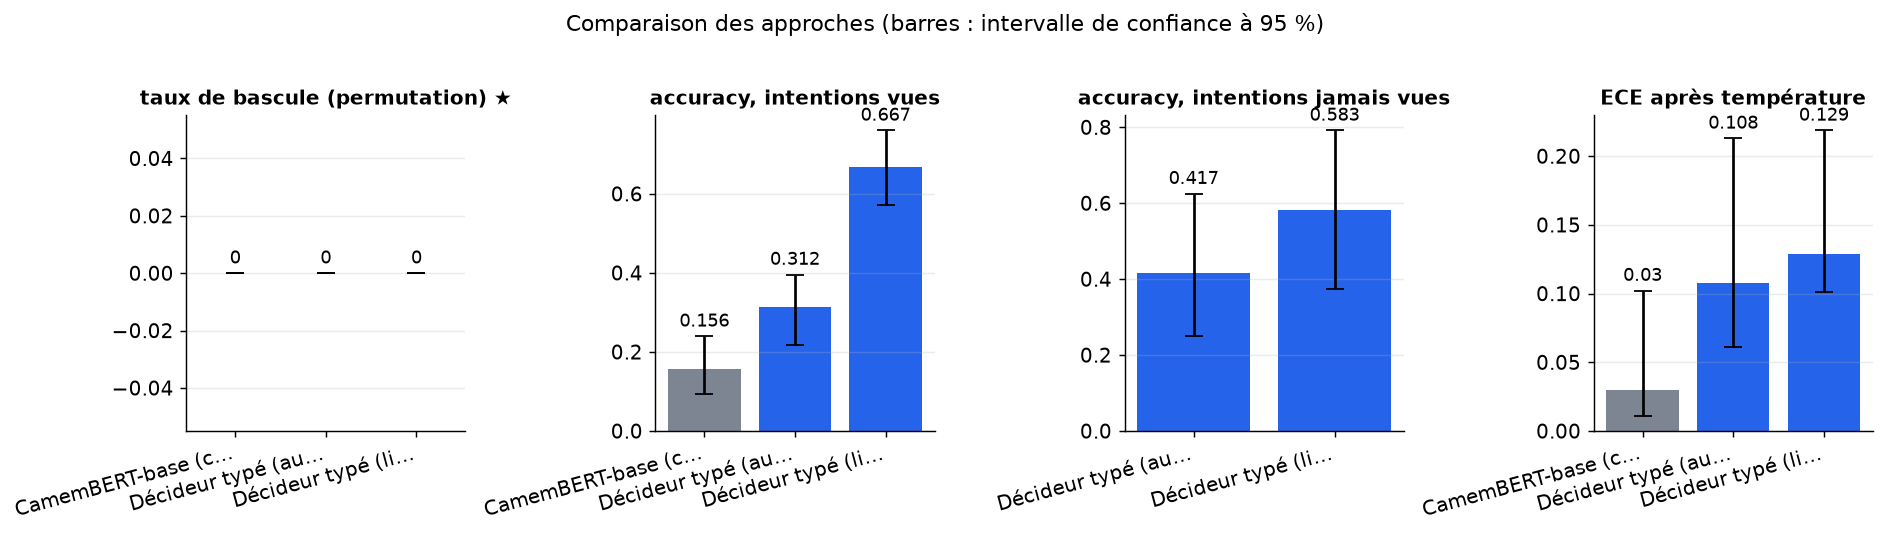

*Figure — Valeur de chaque métrique par approche (★ : métrique principale, à minimiser) ; les barres d'erreur donnent l'intervalle de confiance à 95 % sur 120 exemples de test.*

In [39]:
METRIC_LABELS = {
    "permutation_flip_rate": "taux de bascule (permutation)", "accuracy_seen_classes": "accuracy, intentions vues",
    "accuracy_unseen_classes": "accuracy, intentions jamais vues", "macro_f1": "macro-F1 (intentions vues)",
    "expected_calibration_error": "ECE après température", "scenario_consistency_rate": "erreurs dans le bon scénario",
    "accuracy_vocab_french": "accuracy, libellés reformulés", "accuracy_vocab_truncated": "accuracy, sigles tronqués",
    "accuracy_vocab_opaque": "accuracy, codes opaques"}
ref_metrics, ref_ci = summarize(ref_pred, ref_conf, handles_unseen=False, flips=flipped["reference"])
approaches = [{"name": "CamemBERT-base (classes fixes)", "role": "reference", "metrics": ref_metrics, "ci95": ref_ci,
               "latency_ms": latency_summary["reference"],
               "notes": f"{REF_MODEL_ID}, {len(seen_intents)} classes, époque {ref_info['best_epoch']}/{REF_EPOCHS}, "
                        f"T={ref_info['temperature']:.2f}, choix restreint aux options connues, bascule mesurée sur "
                        f"les ordres {ORDERS} ; test {DATA_FINGERPRINT}"}]
for variant, title in [("augmented", "Décideur typé (augmentation de libellés)"), ("fixed", "Décideur typé (libellés fixes)")]:
    predictions, confidences = decisions[variant][("key", "random")]
    metrics, ci95 = summarize(predictions, confidences, True, flipped[variant],
                              {v: decisions[variant][(v, "random")][0] for v in VOCAB_METRICS})
    info = decider_info[variant]
    approaches.append({"name": title, "role": "new", "metrics": metrics, "ci95": ci95, "latency_ms": latency_summary[variant],
                       "notes": f"{DECIDER_MODEL_ID} cross-encoder, K={TRAIN_OPTIONS_K}, époque {info['best_epoch']}/{DECIDER_EPOCHS}, "
                                f"T={info['temperature']:.2f}, {len(eval_option_sets[0])} options, ordres {ORDERS}, "
                                f"attention {decider_runtime['attention']}, écart entre appels {max_gap:.1e}"})
results = save_results({
    "primary_metric": "permutation_flip_rate", "direction": "min", "metric_labels": METRIC_LABELS,
    "dataset": {**DATASET_INFO, "n_examples": int(n_evaluated)}, "approaches": approaches})
display(results_table(results))
plot_comparison(results, metrics=["permutation_flip_rate", "accuracy_seen_classes", "accuracy_unseen_classes", "expected_calibration_error"])

### Test apparié et verdict sur l'hypothèse

- Le **test de McNemar** ne compte que les questions où **une seule** des deux approches a juste. Si ces désaccords se répartissent à parts égales, l'écart n'est pas significatif.
- **Condition d'éligibilité** : l'intervalle de confiance de l'accuracy (intentions vues) de chaque approche doit dépasser le **niveau trivial**, c'est-à-dire le plus haut du hasard ($1/N$) et de la classe majoritaire. Sinon, les verdicts s'affichent « non concluant ».

In [40]:
chance_level = 1 / len(eval_option_sets[0])
majority_class = train_df["intent"].value_counts().idxmax()
trivial_level = max(chance_level, float(np.mean(true_intents[seen_mask] == majority_class)))
reference_entry, augmented_entry = approaches[0], approaches[1]
eligible = all(entry["ci95"]["accuracy_seen_classes"][0] > trivial_level for entry in (reference_entry, augmented_entry))
ref_correct = ref_pred[seen_mask] == true_intents[seen_mask]
new_correct = decisions["augmented"][("key", "random")][0][seen_mask] == true_intents[seen_mask]
only_ref, only_new = int(np.sum(ref_correct & ~new_correct)), int(np.sum(~ref_correct & new_correct))
p_value = binomtest(only_ref, only_ref + only_new, 0.5).pvalue if only_ref + only_new else 1.0
print(f"McNemar (intentions vues) : {only_ref} justes pour CamemBERT seul, {only_new} pour le décideur seul, p = {p_value:.3g}")
m = augmented_entry["metrics"]
gap = reference_entry["metrics"]["accuracy_seen_classes"] - m["accuracy_seen_classes"]
opaque_low = augmented_entry["ci95"]["accuracy_vocab_opaque"][0]
checks = [("écart d'accuracy (vues) à CamemBERT ≤ 3 points", gap, gap <= 0.03),
          ("taux de bascule < 5 %", m["permutation_flip_rate"], m["permutation_flip_rate"] < 0.05),
          ("accuracy sur intentions jamais vues > 50 %", m["accuracy_unseen_classes"],
           None if m["accuracy_unseen_classes"] is None else m["accuracy_unseen_classes"] > 0.5),
          ("codes opaques proches du hasard (IC bas ≤ 2 × hasard)", m["accuracy_vocab_opaque"], opaque_low <= 2 * chance_level)]

def verdict(passed) -> str:
    """Verdict d'un critère, neutralisé si les approches ne battent pas le prédicteur trivial."""
    if passed is None:
        return "non mesuré"
    if not eligible:
        return "non concluant"
    return "atteint" if passed else "non atteint"

display(pd.DataFrame([{"critère": c, "valeur": None if v is None else round(float(v), 3), "verdict": verdict(p)} for c, v, p in checks]))
print(f"Niveau trivial : {trivial_level:.3f} (hasard 1/{len(eval_option_sets[0])} ou classe majoritaire).")
if not eligible:
    print("Non concluant : au moins une approche ne dépasse pas nettement le prédicteur trivial ; aucun verdict n'est tiré.")

McNemar (intentions vues) : 11 justes pour CamemBERT seul, 26 pour le décideur seul, p = 0.0201


,critère,valeur,verdict
0,écart d'accuracy (vues) à CamemBERT ≤ 3 points,-0.156,non concluant
1,taux de bascule < 5 %,0.000,non concluant
2,accuracy sur intentions jamais vues > 50 %,0.417,non concluant
3,codes opaques proches du hasard (IC bas ≤ 2 × ...,0.158,non concluant


Niveau trivial : 0.125 (hasard 1/8 ou classe majoritaire).
Non concluant : au moins une approche ne dépasse pas nettement le prédicteur trivial ; aucun verdict n'est tiré.


## 6. Analyse des résultats

### Calibration avant et après température

On compare l'ECE sans recalage ($T = 1$) et avec la température apprise sur la validation. Le rapport Drex reconnaît une **surconfiance** de son plus gros modèle et conseille ce recalage.

In [41]:
calibration_rows = []
raw_ref_pred, raw_ref_conf = reference_decisions(ref_test_logits[:n_evaluated], eval_option_sets, 1.0)
candidates = [("CamemBERT-base", raw_ref_pred, raw_ref_conf, ref_pred, ref_conf, ref_info["temperature"])]
for variant, title in [("augmented", "Décideur (augmentation)"), ("fixed", "Décideur (libellés fixes)")]:
    candidates.append((title, *decider_decisions(variant, "key", "random", 1.0), *decisions[variant][("key", "random")],
                       decider_info[variant]["temperature"]))
for title, pred_raw, conf_raw, pred_cal, conf_cal, temperature in candidates:
    correct = (pred_cal[seen_mask] == true_intents[seen_mask]).astype(float)
    calibration_rows.append({"approche": title, "température": round(temperature, 2),
                             "ECE avant": round(expected_calibration_error(correct, conf_raw[seen_mask]), 3),
                             "ECE après": round(expected_calibration_error(correct, conf_cal[seen_mask]), 3),
                             "confiance moyenne": round(float(conf_cal[seen_mask].mean()), 3),
                             "accuracy": round(float(correct.mean()), 3)})
display(pd.DataFrame(calibration_rows))

,approche,température,ECE avant,ECE après,confiance moyenne,accuracy
0,CamemBERT-base,0.23,0.019,0.030,0.186,0.156
1,Décideur (augmentation),0.51,0.132,0.108,0.273,0.312
2,Décideur (libellés fixes),0.88,0.130,0.129,0.638,0.667


### Diagramme de fiabilité

On range les prédictions par confiance. Pour chaque groupe, on porte la confiance moyenne en abscisse et la part de réponses justes en ordonnée. Un modèle bien calibré suit la diagonale ; une courbe **sous** la diagonale signale de la surconfiance.

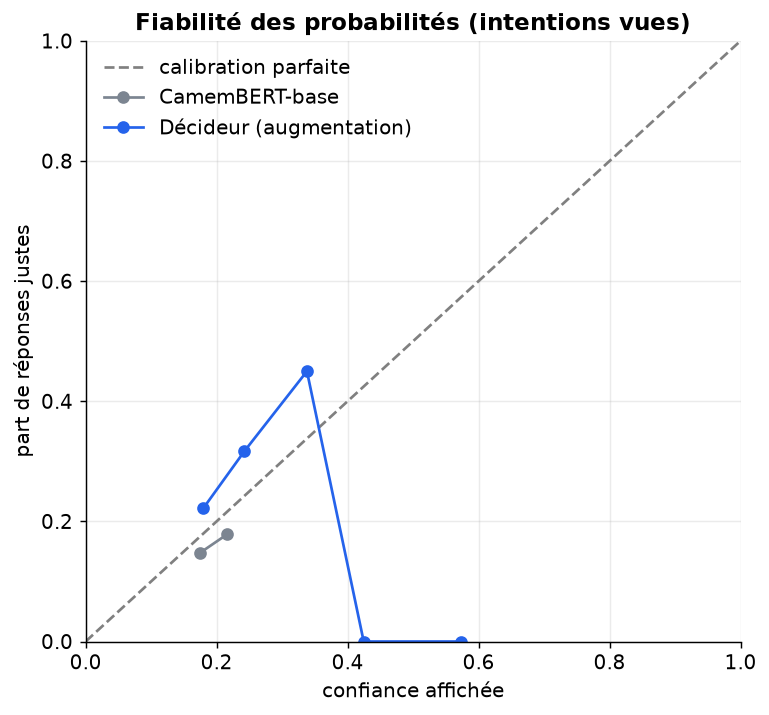

*Figure — Diagramme de fiabilité après température : plus la courbe colle à la diagonale, plus la probabilité affichée correspond à la précision réelle ; sous la diagonale, le modèle est trop sûr de lui.*

In [42]:
def reliability_points(correct: np.ndarray, confidence: np.ndarray, n_bins: int = 10) -> np.ndarray:
    """(confiance moyenne, accuracy, effectif) pour chaque intervalle de confiance non vide."""
    edges = np.linspace(0, 1, n_bins + 1)
    bins = np.clip(np.digitize(confidence, edges[1:-1], right=True), 0, n_bins - 1)
    return np.array([(confidence[bins == b].mean(), correct[bins == b].mean(), (bins == b).sum())
                     for b in range(n_bins) if (bins == b).any()])


fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], "--", color="grey", label="calibration parfaite")
for title, (predictions, confidences), color in [("CamemBERT-base", (ref_pred, ref_conf), COLORS["reference"]),
                                                 ("Décideur (augmentation)", decisions["augmented"][("key", "random")], COLORS["new"])]:
    correct = (predictions[seen_mask] == true_intents[seen_mask]).astype(float)
    points = reliability_points(correct, confidences[seen_mask])
    ax.plot(points[:, 0], points[:, 1], "o-", color=color, label=title)
ax.set(title="Fiabilité des probabilités (intentions vues)", xlabel="confiance affichée",
       ylabel="part de réponses justes", xlim=(0, 1), ylim=(0, 1))
ax.legend()
save_figure(fig, "reliability", "Diagramme de fiabilité après température : plus la courbe colle à la diagonale, "
            "plus la probabilité affichée correspond à la précision réelle ; sous la diagonale, le modèle est trop sûr de lui.")

### Vocabulaire des libellés et taille de l'ensemble d'options

- **À gauche** : l'accuracy de chaque variante du décideur selon la façon d'écrire les libellés. Si l'augmentation aide, l'écart avec la variante fixe doit apparaître sur les vocabulaires reformulés et tronqués.
- **À droite** : l'accuracy quand on ne garde que $n$ options (la bonne et $n-1$ autres tirées parmi les options déjà notées). Cette courbe se calcule sans nouvel appel au modèle.

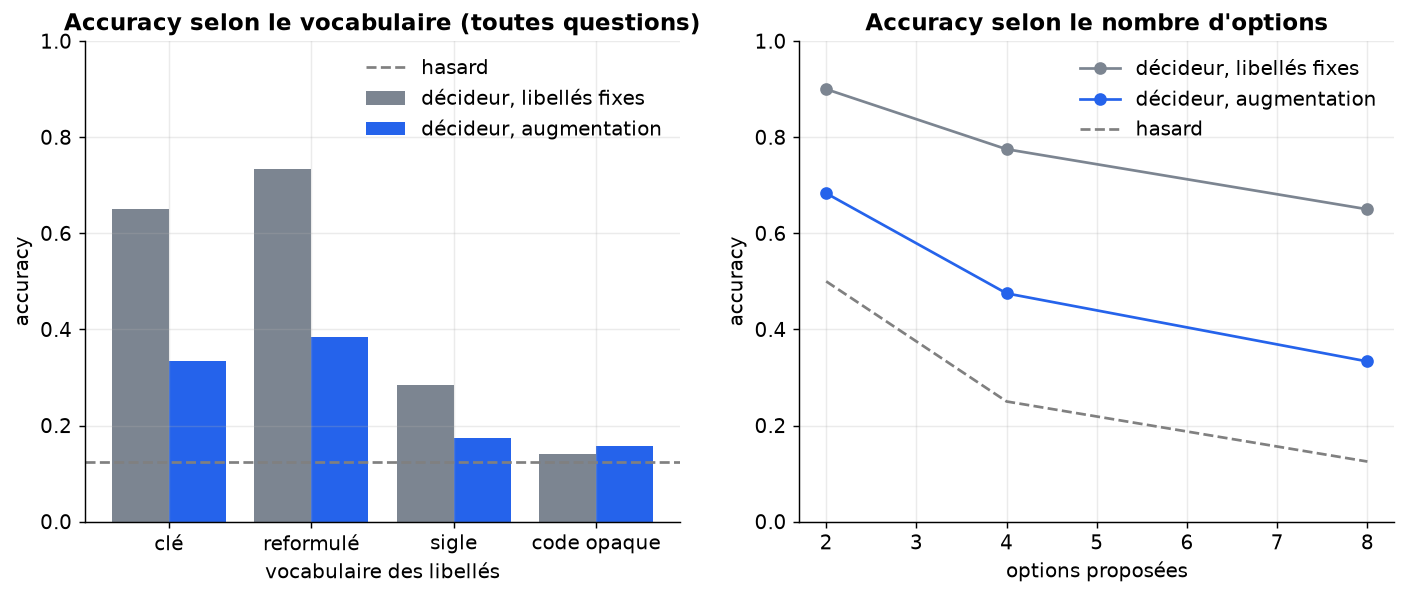

*Figure — À gauche, l'accuracy du décideur selon l'écriture des libellés (la ligne grise marque le hasard). À droite, l'accuracy selon le nombre d'options proposées : la pente montre le coût d'un ensemble plus grand.*

In [43]:
SET_SIZES = by_scale([2, 4, 8], [5, 18, 60])  # tailles d'ensemble d'options testées

def accuracy_for_set_size(variant: str, size: int) -> float:
    """Accuracy du décideur en ne gardant que `size` options, la bonne comprise."""
    rng = np.random.default_rng(SEED)
    hits = []
    for options, scores, truth in zip(eval_option_sets, raw_scores[variant][("key", "random")], true_intents):
        gold = options.index(truth)
        others = [j for j in range(len(options)) if j != gold]
        keep = [gold] + [int(j) for j in rng.choice(others, size=min(size - 1, len(others)), replace=False)]
        hits.append(keep[int(np.argmax(scores[keep]))] == gold)
    return float(np.mean(hits))

vocabularies = ["key", "french", "truncated", "opaque"]
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4.8))
for shift, (variant, title, color) in zip([-0.2, 0.2], [("fixed", "libellés fixes", COLORS["reference"]), ("augmented", "augmentation", COLORS["new"])]):
    values = [accuracy(true_intents, decisions[variant][(v, "random")][0]) for v in vocabularies]
    left.bar(np.arange(len(vocabularies)) + shift, values, width=0.4, color=color, label=f"décideur, {title}")
    right.plot(SET_SIZES, [accuracy_for_set_size(variant, s) for s in SET_SIZES], "o-", color=color, label=f"décideur, {title}")
left.axhline(chance_level, ls="--", color="grey", label="hasard")
left.set_xticks(range(len(vocabularies)), ["clé", "reformulé", "sigle", "code opaque"])
left.set(title="Accuracy selon le vocabulaire (toutes questions)", xlabel="vocabulaire des libellés", ylabel="accuracy", ylim=(0, 1))
right.plot(SET_SIZES, [1 / s for s in SET_SIZES], "--", color="grey", label="hasard")
right.set(title="Accuracy selon le nombre d'options", xlabel="options proposées", ylabel="accuracy", ylim=(0, 1))
left.legend()
right.legend()
save_figure(fig, "vocabulary_and_set_size", "À gauche, l'accuracy du décideur selon l'écriture des libellés (la ligne grise marque le hasard). "
            "À droite, l'accuracy selon le nombre d'options proposées : la pente montre le coût d'un ensemble plus grand.")

### Exemples d'erreurs (phase publique seulement)

Quelques erreurs du décideur avec augmentation, avec sa confiance, en indiquant si l'erreur reste dans le bon scénario. En phase privée, on n'affiche que des agrégats : la répartition des erreurs entre intentions vues et jamais vues.

In [44]:
N_ERROR_EXAMPLES = 8  # erreurs affichées
augmented_pred, augmented_conf = decisions["augmented"][("key", "random")]
error_frame = pd.DataFrame({"texte": eval_df["text"], "attendu": true_intents, "choisi": augmented_pred,
                            "confiance": augmented_conf.round(3), "intention vue": seen_mask,
                            "même scénario": [scenario_of.get(p) == scenario_of[t] for p, t in zip(augmented_pred, true_intents)]})
error_frame = error_frame[error_frame["attendu"] != error_frame["choisi"]]
display(error_frame.groupby("intention vue")[["même scénario"]].agg(["count", "mean"]).round(3))
if PHASE == "public":
    display(error_frame.sort_values("confiance", ascending=False).head(N_ERROR_EXAMPLES))

même scénario       
                      count   mean
intention vue                     
False                    14  0.071
True                     66  0.121

,texte,attendu,choisi,confiance,intention vue,même scénario
2,combien coûte l'action amazon,qa_stock,lists_query,0.579,True,False
78,nouvelle liste,lists_createoradd,lists_query,0.569,True,True
76,lacher une blague,general_joke,play_music,0.453,True,False
38,dis-moi si taco bell livre,takeaway_query,music_dislikeness,0.430,False,False
61,monte- le olly,audio_volume_up,lists_createoradd,0.427,True,False
25,décalage horaire entre ottawa et bruxelles,datetime_convert,lists_query,0.419,True,False
80,affiche la liste des e-mails récent,email_query,lists_query,0.413,True,False
67,chaînes radio,play_radio,takeaway_query,0.411,True,False


### À retenir

- **Éligibilité d'abord.** Si l'intervalle de confiance de l'accuracy ne dépasse pas le niveau trivial, l'expérience est **non concluante** : c'est attendu à l'échelle réduite, avec quelques centaines de textes et une époque. Seule l'échelle complète permet de trancher.
- **Stabilité à l'ordre.** Le décideur note chaque option indépendamment, et CamemBERT ne lit pas la liste. Un taux de bascule proche de 0 pour les deux confirme qu'aucune dépendance à l'ordre ne s'est glissée (lots, rembourrage, égalités). Il ne dit **rien** de la sensibilité à l'ordre des grands modèles qui lisent toutes les options ensemble.
- **Classes jamais vues.** Si l'accuracy sur les intentions jamais vues dépasse nettement le hasard, ajouter une catégorie sans réentraîner devient envisageable. Il faudra le confirmer sur les libellés internes.
- **Les libellés comptent.** Comparer les vocabulaires et les deux variantes montre ce que l'augmentation apporte. Si l'accuracy des codes opaques tombe au niveau du hasard, c'est la preuve que le modèle lit le **sens** des libellés : ils doivent rester parlants.
- **Calibration.** Si l'ECE baisse nettement après température, il faut recaler la température sur chaque jeu de libellés, comme le recommande le rapport Drex.

## 7. Bilan

> **Verdict** (confiance moyenne). À l'échelle réduite (substitut de 140 M de paramètres, 120 questions de test, 1 époque sur 320 textes, 8 options), les chiffres ne permettent pas de trancher. CamemBERT est au niveau du hasard (accuracy 0,156 sur les intentions vues) et son intervalle de confiance ne dépasse pas le niveau trivial. Le décideur à libellés fixes atteint 0,67 et la variante augmentée 0,31, ce qui reflète des budgets d'entraînement très différents, pas un résultat. Le taux de bascule nul est garanti par construction pour les deux approches. Les codes opaques tombent près du hasard (0,16), cohérent avec l'hypothèse mais sur un petit échantillon. Il faut l'échelle complète pour juger l'écart de précision, les intentions jamais vues et l'effet de l'augmentation. Aucune conclusion n'est transposable aux modèles Drex.

*Échelle réduite seulement (120 exemples, CPU) : exception (cellule 59, section new_approach). Ces chiffres valident la mécanique ; ils sont indicatifs et à confirmer avec `SCALE = "full"`.*

| Approche | taux de bascule (permutation) ★ ↓ | accuracy, intentions vues ↑ | accuracy, intentions jamais vues ↑ | macro-F1 (intentions vues) ↑ | ECE après température ↓ | erreurs dans le bon scénario ↑ | accuracy, libellés reformulés ↑ | accuracy, sigles tronqués ↑ | accuracy, codes opaques | Latence médiane (ms) ↓ |
|---|---|---|---|---|---|---|---|---|---|---|
| CamemBERT-base (classes fixes) (référence) | 0 [0 ; 0] | 0,156 [0,0938 ; 0,24] | — | 0,0851 [0,0488 ; 0,127] | **0,03 [0,0107 ; 0,102]** | 0,0741 [0,0247 ; 0,136] | — | — | — | 26,7 |
| Décideur typé (augmentation de libellés) (nouvelle approche) | 0 [0 ; 0] | 0,312 [0,219 ; 0,396] | 0,417 [0,25 ; 0,625] | 0,277 [0,186 ; 0,335] | 0,108 [0,061 ; 0,213] | 0,121 [0,0455 ; 0,197] | 0,383 [0,292 ; 0,475] | 0,175 [0,108 ; 0,242] | 0,158 [0,1 ; 0,225] | 51,6 |
| Décideur typé (libellés fixes) (nouvelle approche) | 0 [0 ; 0] | **0,667 [0,573 ; 0,76]** | 0,583 [0,375 ; 0,792] | **0,652 [0,543 ; 0,714]** | 0,129 [0,101 ; 0,219] | **0,25 [0,125 ; 0,406]** | 0,733 [0,658 ; 0,808] | 0,283 [0,2 ; 0,367] | 0,142 [0,0833 ; 0,208] | 50,9 |

★ métrique principale · ↑ plus haut = meilleur · ↓ plus bas = meilleur · entre crochets : intervalle de confiance à 95 % (bootstrap) · en gras : la meilleure valeur.

**Réserves**

- Un taux de bascule nul ne prouve pas que l'approche soit robuste à l'ordre. Il est nul pour toute architecture qui note les options séparément. Il ne dit rien sur les modèles de décision de la source.
- L'avantage apparent du décideur sur CamemBERT à cette échelle vient surtout d'une référence à peine entraînée. Il ne permet pas de conclure sur l'écart réel.
- Un bon score sur les libellés reformulés ou tronqués est un score sur des formes vues à l'entraînement. Il ne garantit pas la tenue face à des libellés réécrits autrement.

**Limites**

- Le décideur note chaque option indépendamment : un taux de bascule nul est attendu par conception et ne renseigne pas sur la sensibilité à l'ordre des grands modèles qui lisent toutes les options ensemble.
- Les vocabulaires reformulé, tronqué et opaque sont construits par règle, pas rédigés par des experts ; les libellés internes réels peuvent se comporter autrement.
- MASSIVE contient des requêtes courtes d'assistant vocal avec 60 classes équilibrées, loin de messages clients longs et de centaines de sous-motifs déséquilibrés.
- Les intentions jamais vues sont tirées au hasard une seule fois : l'accuracy sur ces classes dépend fortement de ce tirage.
- Avec 60 options, CamemBERT revient à une classification sur 50 classes ; sur moins d'options, il est restreint aux options connues, ce qui l'avantage sur les questions d'intentions vues.

**Échelle réduite : ce qui diffère de l'échelle complète**

- À l'échelle réduite, mmBERT-small remplace mmBERT-base ; la configuration et le tokeniseur de mmBERT-base sont quand même vérifiés. Les tailles sont réduites : 320 textes d'entraînement, 60 de validation, 120 de test. Chaque modèle fait 1 époque, avec K=4 options à l'entraînement et 8 au test au lieu de 60. On teste 2 ordres (aléatoire, inversé) au lieu de 3, avec des séquences de 48 tokens et des tailles d'ensemble de 2, 4 et 8. Les accuracies obtenues ne sont pas interprétables : c'est l'échelle complète qui tranche.

**Améliorations possibles**

- Les ECE de CamemBERT et du décideur ne sont pas strictement comparables. À cette échelle, ils ne servent pas à classer les deux approches.
- Le rapport de latence entre les deux approches est propre à cette configuration réduite. Avec 60 options et le modèle complet, le décideur sera plus lent.
- L'accuracy sur les intentions jamais vues peut être un peu surestimée quand le scénario parent est connu.

**Et ensuite ?** Rejouer le même protocole sur vos données : `PHASE = "private"`, `SCALE = "full"`, après avoir préparé le jeu et la configuration décrits dans le README (section « Sur vos données »).